## PRCP-1001 – Rice Leaf Disease Detection

## 1. Introduction

Rice is one of the most important staple food crops in the world, feeding more than half of the global population and forming the backbone of agricultural economies across Asia and beyond. Because so much depends on healthy rice yields, anything that threatens the crop — including plant diseases — can have serious consequences for food security and farmers' livelihoods.

Rice leaf diseases such as leaf smut, brown spot, and bacterial leaf blight are among the most common threats to rice cultivation. If left undetected or misdiagnosed, these diseases can spread quickly and significantly reduce yield and grain quality. Traditionally, disease identification has relied on manual inspection by farmers or agricultural experts — a process that is time-consuming, requires specialized knowledge, and is prone to human error,especially in resource-limited farming regions where expert access is scarce.

This is where computer vision and deep learning offer real value. By training a model to recognize the visual patterns associated with each disease — lesion shape, color, texture, and distribution on the leaf — it becomes possible to build a tool that can assist in fast, consistent, and accessible disease identification, even by non-experts, simply from a photograph of an affected leaf. This project explores exactly that: using image classification techniques to automatically distinguish between three major rice leaf diseases.

## 2. Problem Statement

Given a dataset of rice leaf images, each belonging to one of three disease categories — leaf smut, brown spot, and bacterial leaf blight — the goal is to build a model that can classify a new, unseen rice leaf image into its correct disease category. The project additionally requires a thorough data analysis of the image dataset, an investigation into how techniques like data augmentation affect model performance, and a report comparing multiple modeling approaches to recommend the most suitable one for real-world use.

A key characteristic of this problem — and something that will shape nearly every decision going forward — is that the dataset is very small: only 120 images total, just 40 per class. This is a realistic but genuinely challenging constraint, and it means the project isn't just about building a classifier, but about building one responsibly given limited data, with careful attention to overfitting and generalization.

## 3. Objectives
1) Thoroughly understand and analyze the rice leaf image dataset — its structure, class balance, image properties, and quality — before any modeling begins.
2) Design a preprocessing and data-splitting strategy appropriate for a very small image dataset, with explicit safeguards against data leakage.
3) Investigate the effect of data augmentation as a technique to compensate for the limited amount of training data, comparing results with and without it.
4) Build and evaluate a baseline CNN, then compare it against transfer-learning approaches (e.g., MobileNetV2, EfficientNet) to see whether pretrained visual knowledge improves performance on this small dataset.
5) Evaluate all models using metrics appropriate for a small, multiclass image classification problem (accuracy, precision, recall, F1, macro F1, confusion matrices), and analyze overfitting and misclassifications honestly.
6) Select the best-performing, most practical model for production use — based on generalization and deployability, not just raw training accuracy — and clearly document the reasoning, challenges faced, and limitations of the final solution.

## 4. Scope of the Project

This project covers the complete pipeline from raw image data to a deployable-quality classifier recommendation: dataset understanding, preprocessing, augmentation experimentation, baseline and transfer-learning model development, evaluation, error analysis, and basic explainability (Grad-CAM, if feasible given the small dataset and compute constraints).

It is scoped specifically to the 3 disease classes present in this dataset (leaf smut, brown spot, bacterial leaf blight) and does not attempt to generalize to rice diseases outside these categories, nor to handle images captured under conditions very different from the dataset (e.g., extreme lighting, non-leaf backgrounds) without explicitly noting that as a limitation. Given the dataset size (120 images), the scope deliberately avoids very large or highly complex architectures that would be prone to overfitting, and instead focuses on techniques suited to low-data regimes: augmentation and transfer learning.

## 5. Dataset Description

The dataset used for this project contains 120 JPG images of rice leaves, evenly distributed across 3 disease classes, with 40 images per class:

- Leaf smut
- Brown spot
- Bacterial leaf blight

Each image shows a rice leaf affected by one of these three diseases, and the task is to classify a given leaf image into the correct disease category. Since the dataset is very small (only 120 images total, and just 40 per class), this description will be expanded with actual measured details — image dimensions, formats, and any data quality issues — once the images are loaded and inspected in the Dataset Understanding section.

## 6. Project Workflow

1. Dataset Understanding — load images, check counts/classes/dimensions/formats, check for corrupt or duplicate images, visualize samples and class distribution.
2. Data Preprocessing — resizing, normalization, label encoding, stratified train/validation/test split with leakage prevention.
3. Exploratory Image Analysis — visual inspection across classes, dimension/brightness/color checks.
4. Data Augmentation Experiment — Experiment A (no augmentation) vs Experiment B (with augmentation), compared on actual results.
5. Baseline CNN — a simple custom architecture, trained with regularization and callbacks (EarlyStopping, ModelCheckpoint), training/validation curves reviewed for overfitting.
6. Transfer Learning — MobileNetV2 and EfficientNet, frozen base + trained head, then selective fine-tuning.
7. Hyperparameter Experimentation — a small, deliberate set of experiments (not a large grid search), given the dataset size.
8. Model Evaluation — full metric suite (accuracy, precision, recall, F1, macro F1, confusion matrix) on validation/test data.
9. Error Analysis — inspecting actual misclassified images, prediction confidence, and plausible visual reasons for errors.
10. Model Explainability — Grad-CAM on the best model, if feasible, with a clear statement of its limitations.
11. Model Comparison — a single comparison table across all actually-trained models, with no fabricated values.
12. Best Model Selection — based on generalization, complexity, and deployability, not training accuracy alone.
13. Challenges Report — a table of actual observed challenges, evidence, techniques used, and reasoning.
14. Technique Analysis Report — discussion of the effect of each technique used, grounded in what was actually observed.
15. Production Recommendation — practical deployment considerations and honest limitations given the small dataset.
16. Final Conclusion & Future Enhancements.

## 7. Proposed Advanced Methodology

The proposed approach is to treat this as a small-data image classification problem and lean on techniques specifically suited to that setting, rather than applying a generic "big CNN" solution: starting with thorough exploratory analysis, careful preprocessing with leakage prevention, a controlled data augmentation experiment, a baseline CNN followed by transfer learning (MobileNetV2, EfficientNet) with frozen-then-fine-tuned layers, honest multi-metric evaluation, error analysis, and Grad-CAM explainability where feasible — selecting the final model based on generalization and practicality rather than raw training accuracy.

Given the constraint of only 120 total images, the methodology is deliberately designed around small-data best practices rather than deep-learning-at-scale defaults:

- Data augmentation is treated as an experiment, not an assumption — we'll measure whether it actually helps this dataset (e.g., certain augmentations like flips may be fine, but aggressive distortions could risk altering disease-relevant lesion characteristics, so each transformation will be justified individually rather than applied blindly).
- Transfer learning is prioritized over training deep CNNs from scratch — with so few images per class (~40), a custom CNN trained from scratch is at high risk of overfitting or simply not learning generalizable features. Pretrained models (MobileNetV2, EfficientNet) bring in visual features learned from millions of ImageNet images, which is likely to matter a lot here.
- A frozen-then-fine-tune strategy is used for transfer learning: first train only the classification head (keeping pretrained weights frozen) to avoid destroying useful pretrained features early, then cautiously fine-tune a limited number of top layers if it's justified by validation performance.
- Regularization and early stopping are used throughout (dropout, batch normalization, EarlyStopping, ReduceLROnPlateau) specifically because overfitting is the primary risk with this dataset size, not an incidental concern.
- Evaluation goes beyond accuracy — with only a small test set, accuracy alone can be noisy and misleading, so macro F1, per-class precision/recall, and confusion matrices will be used to get a fuller, more honest picture of performance across all three classes.
- Explainability (Grad-CAM) is included specifically to sanity-check whether the model is actually attending to leaf/lesion regions, rather than to background artifacts — an important trust check when working with so little training data.

## 8. Technologies and Libraries

- Python — core language for the entire project.
- NumPy / Pandas — numerical operations and any tabular bookkeeping (e.g., file paths, labels, results tables).
- Matplotlib / Seaborn — visualizations: class distribution, sample image grids, training curves, confusion matrices.
- OpenCV / PIL — image loading, validation, resizing, and basic image-property inspection (dimensions, corrupt file checks).
- TensorFlow / Keras — building the baseline CNN, applying transfer learning (MobileNetV2, EfficientNet), data augmentation pipelines, training callbacks.
- Scikit-learn — train/test/validation splitting with stratification, classification metrics (precision, recall, F1, confusion matrix, classification report).
- Grad-CAM implementation — likely via a lightweight custom implementation using Keras/TensorFlow gradients, used later if computationally feasible.

Each library will be imported at the point it's actually needed in the notebook, rather than front-loaded all at once.

## Section 2: Dataset Understanding

Before any preprocessing or modeling, we need to inspect what we actually have: are all images present and readable, are they consistent in format, and is the class split really balanced as documented. We start by downloading, extracting, and doing a first structural pass — file counts per class, formats, and folder layout — before moving to visual inspection (sample grids, dimension distributions, corruption checks) in the next step.

In [1]:
# ============================================
# Step 2a - Download, extract, and inventory the dataset
# ============================================

import os
import zipfile
import urllib.request
from collections import Counter

# ---- Download the dataset zip ----
DATA_URL = "https://d3ilbtxij3aepc.cloudfront.net/projects/CDS-Capstone-Projects/PRCP-1001-RiceLeaf.zip"
ZIP_PATH = "/content/PRCP-1001-RiceLeaf.zip"
EXTRACT_DIR = "/content/PRCP-1001-RiceLeaf"

if not os.path.exists(ZIP_PATH):
    print("Downloading dataset...")
    urllib.request.urlretrieve(DATA_URL, ZIP_PATH)
    print("Download complete.")
else:
    print("Zip already downloaded.")

# ---- Extract the zip ----
os.makedirs(EXTRACT_DIR, exist_ok=True)
with zipfile.ZipFile(ZIP_PATH, "r") as zf:
    zf.extractall(EXTRACT_DIR)

# ---- Walk the extracted directory and list everything found ----
print("\nExtracted folder structure:")
for root, dirs, files in os.walk(EXTRACT_DIR):
    level = root.replace(EXTRACT_DIR, "").count(os.sep)
    indent = "  " * level
    print(f"{indent}{os.path.basename(root)}/")
    sub_indent = "  " * (level + 1)
    for f in files[:5]:
        print(f"{sub_indent}{f}")
    if len(files) > 5:
        print(f"{sub_indent}... ({len(files)} files total in this folder)")

Download complete.

Extracted folder structure:
PRCP-1001-RiceLeaf/
  Data/
    Leaf smut-20200814T055530Z-001.zip
    Brown spot-20200814T055208Z-001.zip
    Bacterial leaf blight-20200814T055237Z-001.zip


In [2]:
# ============================================
# Step 2b - Extract the nested per-class zip files
# ============================================

DATA_DIR = "/content/PRCP-1001-RiceLeaf/Data"

# ---- Find all nested zip files inside Data/ ----
nested_zips = [f for f in os.listdir(DATA_DIR) if f.lower().endswith(".zip")]
print("Nested zip files found:")
for z in nested_zips:
    print(" -", z)

# ---- Extract each nested zip into the same Data/ directory ----
for z in nested_zips:
    zip_path = os.path.join(DATA_DIR, z)
    with zipfile.ZipFile(zip_path, "r") as zf:
        zf.extractall(DATA_DIR)
    print(f"Extracted: {z}")

# ---- Now walk the Data/ directory again to see the real structure ----
print("\nFinal folder structure after extracting nested zips:")
for root, dirs, files in os.walk(DATA_DIR):
    level = root.replace(DATA_DIR, "").count(os.sep)
    indent = "  " * level
    print(f"{indent}{os.path.basename(root)}/")
    sub_indent = "  " * (level + 1)
    image_files = [f for f in files if f.lower().endswith((".jpg", ".jpeg", ".png"))]
    other_files = [f for f in files if not f.lower().endswith((".jpg", ".jpeg", ".png"))]
    for f in image_files[:3]:
        print(f"{sub_indent}{f}")
    if len(image_files) > 3:
        print(f"{sub_indent}... ({len(image_files)} image files total in this folder)")
    for f in other_files:
        print(f"{sub_indent}[non-image] {f}")

Nested zip files found:
 - Leaf smut-20200814T055530Z-001.zip
 - Brown spot-20200814T055208Z-001.zip
 - Bacterial leaf blight-20200814T055237Z-001.zip
Extracted: Leaf smut-20200814T055530Z-001.zip
Extracted: Brown spot-20200814T055208Z-001.zip
Extracted: Bacterial leaf blight-20200814T055237Z-001.zip

Final folder structure after extracting nested zips:
Data/
  [non-image] Leaf smut-20200814T055530Z-001.zip
  [non-image] Brown spot-20200814T055208Z-001.zip
  [non-image] Bacterial leaf blight-20200814T055237Z-001.zip
  Brown spot/
    DSC_0300.JPG
    DSC_0302.JPG
    DSC_0119.jpg
    ... (40 image files total in this folder)
  Leaf smut/
    DSC_0312.JPG
    DSC_0328.jpg
    DSC_0505.jpg
    ... (39 image files total in this folder)
  Bacterial leaf blight/
    DSC_0380.JPG
    DSC_0367.JPG
    DSC_0377.JPG
    ... (40 image files total in this folder)


In [3]:
# ============================================
# Step 2c - Count images, check formats, dimensions, and corruption
# ============================================

from PIL import Image
import pandas as pd

CLASS_DIRS = {
    "Brown spot": os.path.join(DATA_DIR, "Brown spot"),
    "Leaf smut": os.path.join(DATA_DIR, "Leaf smut"),
    "Bacterial leaf blight": os.path.join(DATA_DIR, "Bacterial leaf blight"),
}

records = []  # will hold one row per image: class, filename, extension, width, height, mode, corrupt flag

for class_name, folder in CLASS_DIRS.items():
    all_files = os.listdir(folder)
    image_files = [f for f in all_files if f.lower().endswith((".jpg", ".jpeg", ".png"))]

    for fname in image_files:
        fpath = os.path.join(folder, fname)
        ext = os.path.splitext(fname)[1]
        try:
            with Image.open(fpath) as img:
                img.verify()  # checks the file is a valid, non-corrupt image
            # re-open after verify() (verify() closes usability for further reads)
            with Image.open(fpath) as img:
                width, height = img.size
                mode = img.mode
            corrupt = False
        except Exception as e:
            width, height, mode = None, None, None
            corrupt = True

        records.append({
            "class": class_name,
            "filename": fname,
            "extension": ext,
            "width": width,
            "height": height,
            "mode": mode,
            "corrupt": corrupt
        })

inventory_df = pd.DataFrame(records)

# ---- Class counts ----
print("Image counts per class:")
print(inventory_df["class"].value_counts())
print()

# ---- File extension breakdown ----
print("File extension counts:")
print(inventory_df["extension"].value_counts())
print()

# ---- Corrupt file check ----
num_corrupt = inventory_df["corrupt"].sum()
print(f"Number of corrupt/unreadable images: {num_corrupt}")
if num_corrupt > 0:
    print(inventory_df[inventory_df["corrupt"]])
print()

# ---- Image dimension summary ----
print("Image dimension summary (width x height):")
print(inventory_df[["width", "height"]].describe())
print()

# ---- Unique dimensions found ----
unique_dims = inventory_df.dropna(subset=["width", "height"]).groupby(["width", "height"]).size().reset_index(name="count")
print("Unique (width, height) combinations found:")
print(unique_dims.sort_values("count", ascending=False))
print()

# ---- Color mode check (e.g., RGB vs grayscale) ----
print("Image color mode counts:")
print(inventory_df["mode"].value_counts())

Image counts per class:
class
Brown spot               40
Bacterial leaf blight    40
Leaf smut                39
Name: count, dtype: int64

File extension counts:
extension
.JPG    67
.jpg    52
Name: count, dtype: int64

Number of corrupt/unreadable images: 0

Image dimension summary (width x height):
             width      height
count   119.000000  119.000000
mean   2383.638655  707.739496
std    1123.528972  311.657582
min     250.000000   71.000000
25%    1074.000000  377.000000
50%    3081.000000  897.000000
75%    3081.000000  897.000000
max    3081.000000  900.000000

Unique (width, height) combinations found:
    width  height  count
33   3081     897     85
0     250     200      2
1     286      92      1
2     296      88      1
4     311     170      1
3     301      71      1
6     340      94      1
7     359     168      1
8     367      73      1
5     316     127      1
10    427     193      1
11    456     124      1
12    467     104      1
13    503     174     

Number of duplicate file groups: 0
No exact duplicate images found.


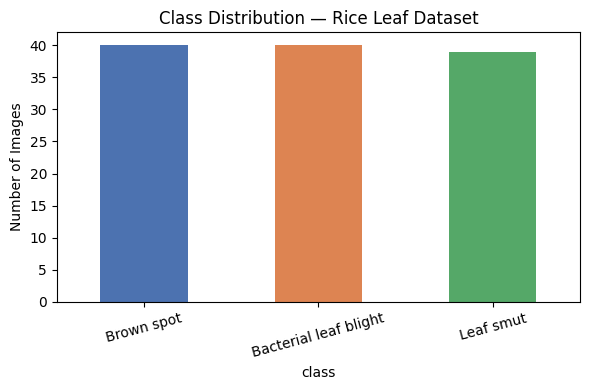

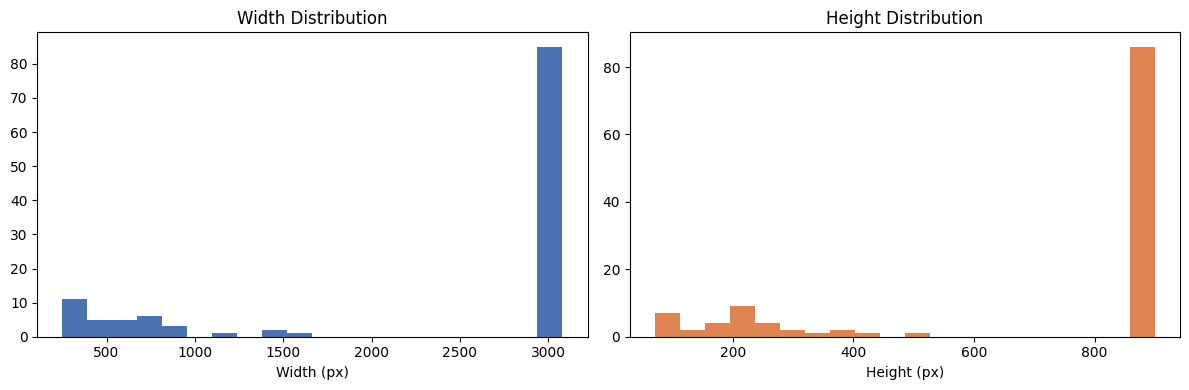

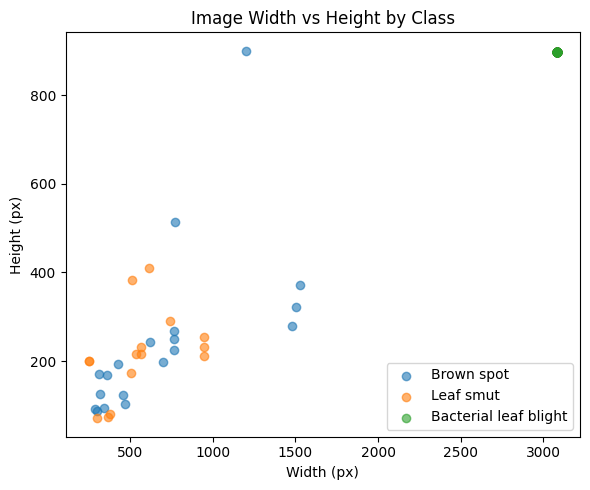

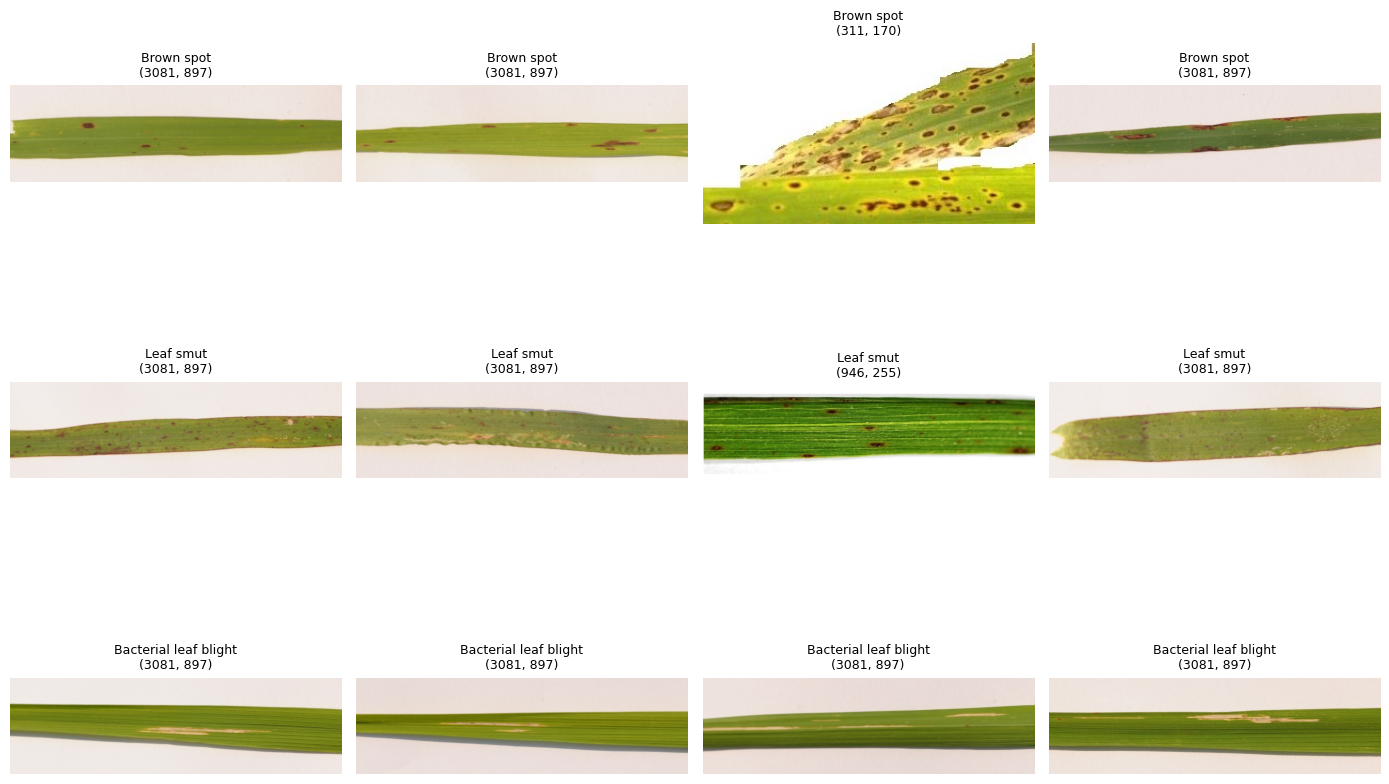

In [4]:
# ============================================
# Step 2d - Duplicate check + required visualizations
# ============================================

import hashlib
import matplotlib.pyplot as plt

# ---- Rebuild full file paths for hashing ----
def get_filepath(row):
    return os.path.join(CLASS_DIRS[row["class"]], row["filename"])

inventory_df["filepath"] = inventory_df.apply(get_filepath, axis=1)

# ---- 2d-i. Duplicate check via MD5 hash of file contents ----
def file_hash(path):
    with open(path, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

inventory_df["hash"] = inventory_df["filepath"].apply(file_hash)

dup_counts = inventory_df["hash"].value_counts()
duplicate_hashes = dup_counts[dup_counts > 1]

print(f"Number of duplicate file groups: {len(duplicate_hashes)}")
if len(duplicate_hashes) > 0:
    print("\nDuplicate files:")
    print(inventory_df[inventory_df["hash"].isin(duplicate_hashes.index)][["class", "filename", "hash"]])
else:
    print("No exact duplicate images found.")

# ---- 2d-ii. Class distribution chart ----
plt.figure(figsize=(6, 4))
inventory_df["class"].value_counts().plot(kind="bar", color=["#4C72B0", "#DD8452", "#55A868"])
plt.title("Class Distribution — Rice Leaf Dataset")
plt.ylabel("Number of Images")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# ---- 2d-iii. Image dimension distribution ----
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(inventory_df["width"], bins=20, color="#4C72B0")
axes[0].set_title("Width Distribution")
axes[0].set_xlabel("Width (px)")

axes[1].hist(inventory_df["height"], bins=20, color="#DD8452")
axes[1].set_title("Height Distribution")
axes[1].set_xlabel("Height (px)")
plt.tight_layout()
plt.show()

# Scatter of width vs height, colored by class, to see aspect ratio patterns per class
plt.figure(figsize=(6, 5))
for class_name in CLASS_DIRS.keys():
    subset = inventory_df[inventory_df["class"] == class_name]
    plt.scatter(subset["width"], subset["height"], label=class_name, alpha=0.6)
plt.xlabel("Width (px)")
plt.ylabel("Height (px)")
plt.title("Image Width vs Height by Class")
plt.legend()
plt.tight_layout()
plt.show()

# ---- 2d-iv. Sample image grid: a few images from each class ----
fig, axes = plt.subplots(3, 4, figsize=(14, 10))
for row_idx, (class_name, folder) in enumerate(CLASS_DIRS.items()):
    sample_files = inventory_df[inventory_df["class"] == class_name]["filename"].head(4).tolist()
    for col_idx, fname in enumerate(sample_files):
        img_path = os.path.join(folder, fname)
        img = Image.open(img_path)
        axes[row_idx, col_idx].imshow(img)
        axes[row_idx, col_idx].set_title(f"{class_name}\n{img.size}", fontsize=9)
        axes[row_idx, col_idx].axis("off")
plt.tight_layout()
plt.show()

In [5]:
# ============================================
# Step 2e - Verify possible size-based shortcut risk
# ============================================

# Cross-tabulate class vs whether each image is the dominant size (3081, 897)
inventory_df["is_dominant_size"] = (inventory_df["width"] == 3081) & (inventory_df["height"] == 897)

size_class_crosstab = pd.crosstab(inventory_df["class"], inventory_df["is_dominant_size"])
print("Class vs. whether image is exactly 3081x897:")
print(size_class_crosstab)
print()

# Show the % of each class that is this dominant size
size_class_pct = pd.crosstab(inventory_df["class"], inventory_df["is_dominant_size"], normalize="index") * 100
print("Percentage of each class at this dominant size:")
print(size_class_pct.round(1))

Class vs. whether image is exactly 3081x897:
is_dominant_size       False  True 
class                              
Bacterial leaf blight      0     40
Brown spot                19     21
Leaf smut                 15     24

Percentage of each class at this dominant size:
is_dominant_size       False  True 
class                              
Bacterial leaf blight    0.0  100.0
Brown spot              47.5   52.5
Leaf smut               38.5   61.5


## Section 3: Data Preprocessing

In [6]:
# ============================================
# Step 3a - Build a clean labeled file list
# ============================================

# We already have inventory_df from Section 2 with filepath + class.
# Keep only the columns we need going forward, and reset the index.

dataset_df = inventory_df[["filepath", "class"]].copy().reset_index(drop=True)

print("Total labeled images:", len(dataset_df))
print("\nClass counts:")
print(dataset_df["class"].value_counts())
print("\nSample rows:")
print(dataset_df.sample(5, random_state=42))

Total labeled images: 119

Class counts:
class
Brown spot               40
Bacterial leaf blight    40
Leaf smut                39
Name: count, dtype: int64

Sample rows:
                                             filepath                  class
56  /content/PRCP-1001-RiceLeaf/Data/Leaf smut/DSC...              Leaf smut
89  /content/PRCP-1001-RiceLeaf/Data/Bacterial lea...  Bacterial leaf blight
4   /content/PRCP-1001-RiceLeaf/Data/Brown spot/DS...             Brown spot
45  /content/PRCP-1001-RiceLeaf/Data/Leaf smut/DSC...              Leaf smut
26  /content/PRCP-1001-RiceLeaf/Data/Brown spot/DS...             Brown spot


In [7]:
# ============================================
# Step 3b - Stratified Train/Validation/Test Split
# ============================================

from sklearn.model_selection import train_test_split

RANDOM_STATE = 42

# ---- First split off the Test set (15%) ----
train_val_df, test_df = train_test_split(
    dataset_df,
    test_size=0.15,
    stratify=dataset_df["class"],
    random_state=RANDOM_STATE
)

# ---- Split the remainder into Train and Validation ----
# 0.15 / 0.85 of the remainder gives ~15% of the original total
val_ratio = 0.15 / 0.85

train_df, val_df = train_test_split(
    train_val_df,
    test_size=val_ratio,
    stratify=train_val_df["class"],
    random_state=RANDOM_STATE
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Split sizes:")
print(f"Train:      {len(train_df)} images")
print(f"Validation: {len(val_df)} images")
print(f"Test:       {len(test_df)} images")
print()

print("Class distribution per split:\n")
print("Train:")
print(train_df["class"].value_counts())
print("\nValidation:")
print(val_df["class"].value_counts())
print("\nTest:")
print(test_df["class"].value_counts())
print()

# ---- Leakage sanity check: confirm no filepath appears in more than one split ----
train_paths = set(train_df["filepath"])
val_paths = set(val_df["filepath"])
test_paths = set(test_df["filepath"])

overlap_train_val = train_paths & val_paths
overlap_train_test = train_paths & test_paths
overlap_val_test = val_paths & test_paths

print("Leakage check (should all be 0):")
print("Train/Val overlap:", len(overlap_train_val))
print("Train/Test overlap:", len(overlap_train_test))
print("Val/Test overlap:", len(overlap_val_test))

Split sizes:
Train:      83 images
Validation: 18 images
Test:       18 images

Class distribution per split:

Train:
class
Brown spot               28
Bacterial leaf blight    28
Leaf smut                27
Name: count, dtype: int64

Validation:
class
Brown spot               6
Leaf smut                6
Bacterial leaf blight    6
Name: count, dtype: int64

Test:
class
Leaf smut                6
Brown spot               6
Bacterial leaf blight    6
Name: count, dtype: int64

Leakage check (should all be 0):
Train/Val overlap: 0
Train/Test overlap: 0
Val/Test overlap: 0


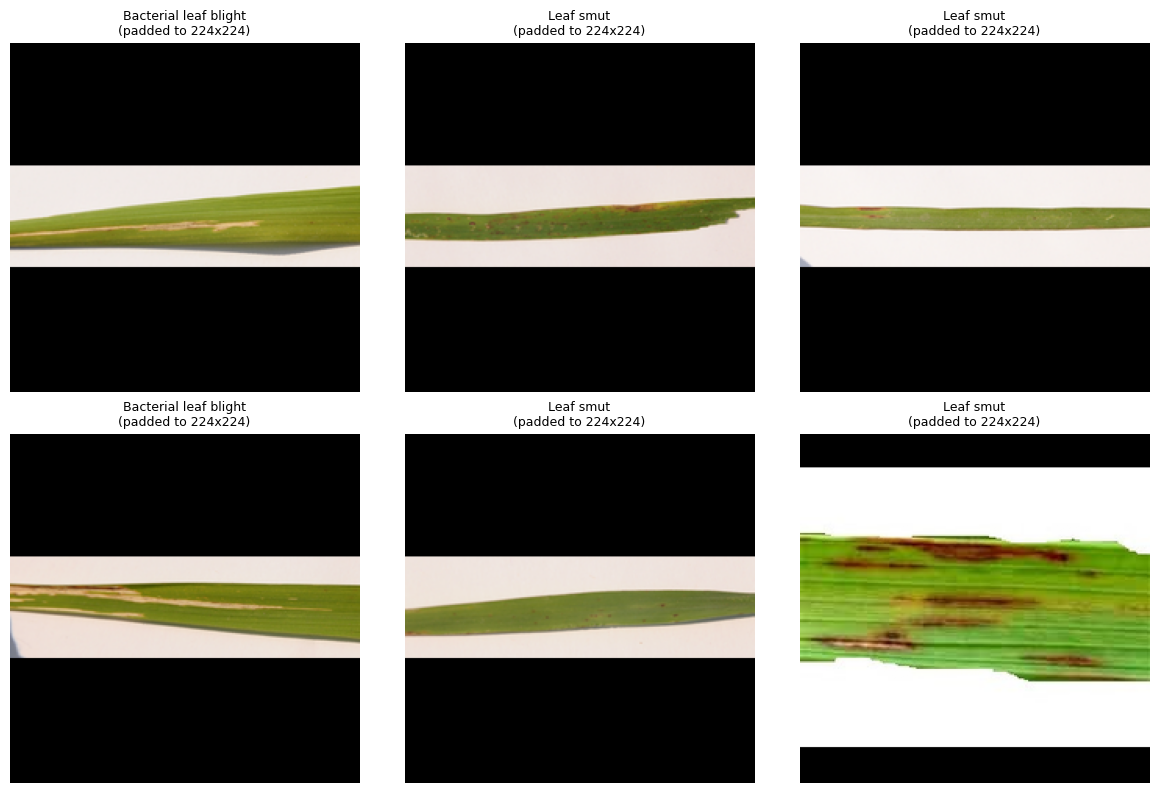

Preprocessing function ready. Example output shape: (224, 224, 3)
Example pixel value range: 0.0 to 0.9607843


In [8]:
# ============================================
# Step 3c - Aspect-ratio-preserving resize + padding function
# ============================================

import numpy as np
from PIL import Image, ImageOps

TARGET_SIZE = 224  # standard input size for MobileNetV2 / EfficientNet

def load_and_preprocess_image(filepath, target_size=TARGET_SIZE):
    """
    Loads an image, resizes it (preserving aspect ratio) so the longer
    side equals target_size, then pads the shorter side with black
    to reach a final (target_size x target_size) square image.
    Returns a normalized numpy array (pixel values in [0, 1]).
    """
    img = Image.open(filepath).convert("RGB")

    # Resize preserving aspect ratio (longer side -> target_size)
    img.thumbnail((target_size, target_size), Image.LANCZOS)

    # Pad to exactly target_size x target_size (centered), black padding
    delta_w = target_size - img.width
    delta_h = target_size - img.height
    padding = (delta_w // 2, delta_h // 2, delta_w - delta_w // 2, delta_h - delta_h // 2)
    img_padded = ImageOps.expand(img, padding, fill=(0, 0, 0))

    # Convert to normalized numpy array
    img_array = np.array(img_padded, dtype=np.float32) / 255.0

    return img_array

# ---- Quick visual test: apply to a few sample images from different original sizes/classes ----
import matplotlib.pyplot as plt

test_samples = dataset_df.sample(6, random_state=1)

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, (_, row) in zip(axes.flatten(), test_samples.iterrows()):
    processed = load_and_preprocess_image(row["filepath"])
    ax.imshow(processed)
    ax.set_title(f"{row['class']}\n(padded to {TARGET_SIZE}x{TARGET_SIZE})", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

print("Preprocessing function ready. Example output shape:", load_and_preprocess_image(dataset_df.iloc[0]["filepath"]).shape)
print("Example pixel value range:", load_and_preprocess_image(dataset_df.iloc[0]["filepath"]).min(), "to", load_and_preprocess_image(dataset_df.iloc[0]["filepath"]).max())

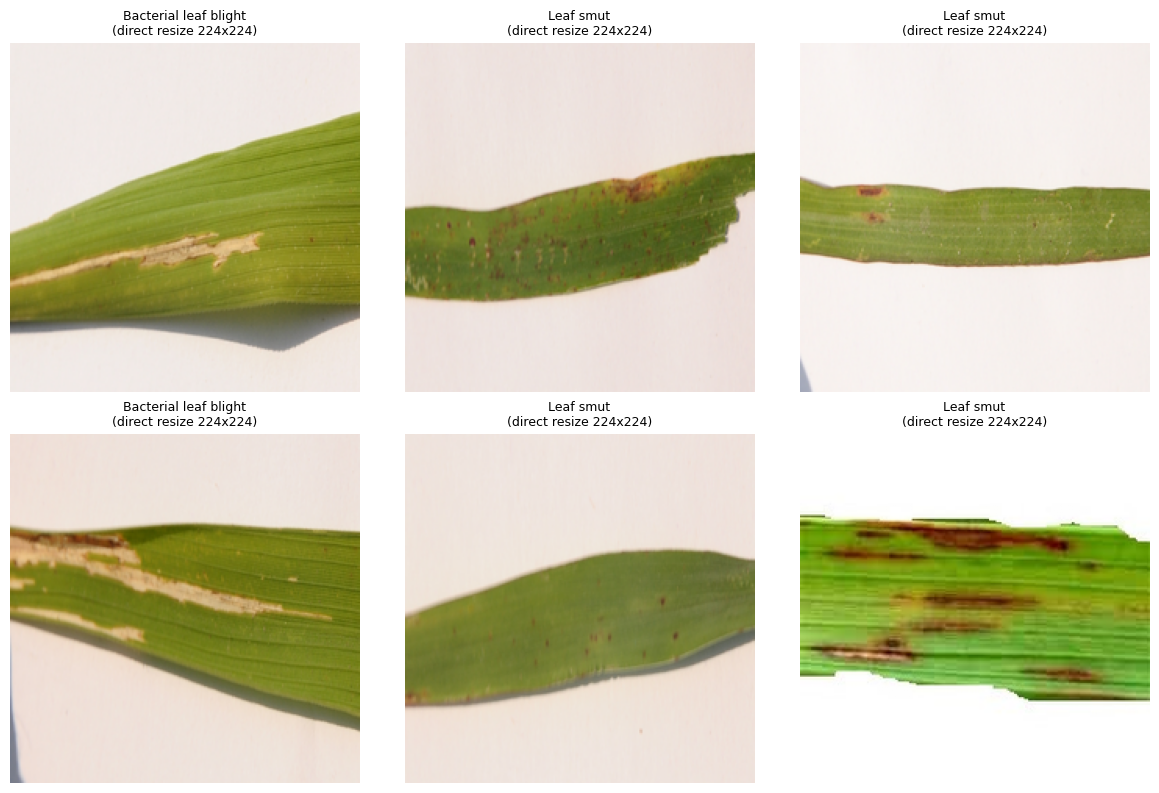

Preprocessing function ready. Example output shape: (224, 224, 3)
Example pixel value range: 0.050980393 to 0.9529412


In [9]:
# ============================================
# Step 3c (REVISED) - Direct resize to 224x224
#
# Note: We initially tried an aspect-ratio-preserving resize with
# padding (see prior experiment). While it avoided distortion, it
# resulted in large black padding regions (often 50%+ of the image),
# since most source images are extremely wide/thin leaf strips.
# This wastes model input resolution on non-informative pixels.
# Since disease lesions do not have a strict shape that a mild
# aspect-ratio stretch would meaningfully corrupt, we switch to a
# direct resize to make full use of the available resolution.
# ============================================

import numpy as np
from PIL import Image

TARGET_SIZE = 224

def load_and_preprocess_image(filepath, target_size=TARGET_SIZE):
    """
    Loads an image and directly resizes it to (target_size x target_size),
    without preserving aspect ratio. Returns a normalized numpy array
    (pixel values in [0, 1]).
    """
    img = Image.open(filepath).convert("RGB")
    img_resized = img.resize((target_size, target_size), Image.LANCZOS)
    img_array = np.array(img_resized, dtype=np.float32) / 255.0
    return img_array

# ---- Quick visual test on the same 6 samples as before, for direct comparison ----
import matplotlib.pyplot as plt

test_samples = dataset_df.sample(6, random_state=1)  # same random_state as before -> same images

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, (_, row) in zip(axes.flatten(), test_samples.iterrows()):
    processed = load_and_preprocess_image(row["filepath"])
    ax.imshow(processed)
    ax.set_title(f"{row['class']}\n(direct resize {TARGET_SIZE}x{TARGET_SIZE})", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

print("Preprocessing function ready. Example output shape:", load_and_preprocess_image(dataset_df.iloc[0]["filepath"]).shape)
print("Example pixel value range:", load_and_preprocess_image(dataset_df.iloc[0]["filepath"]).min(), "to", load_and_preprocess_image(dataset_df.iloc[0]["filepath"]).max())

In [10]:
# ============================================
# Step 3d - Build final image arrays and encoded labels
# ============================================

from sklearn.preprocessing import LabelEncoder

# ---- Fit label encoder on the full class set (consistent across all splits) ----
label_encoder = LabelEncoder()
label_encoder.fit(dataset_df["class"])

print("Class label mapping:")
for i, class_name in enumerate(label_encoder.classes_):
    print(f"  {i} -> {class_name}")

def build_arrays(df, label_encoder):
    """Loads/preprocesses every image in df, returns (X, y) as numpy arrays."""
    X = np.stack([load_and_preprocess_image(fp) for fp in df["filepath"]])
    y = label_encoder.transform(df["class"])
    return X, y

# ---- Build arrays for each split ----
X_train, y_train = build_arrays(train_df, label_encoder)
X_val, y_val = build_arrays(val_df, label_encoder)
X_test, y_test = build_arrays(test_df, label_encoder)

print("\nFinal array shapes:")
print("X_train:", X_train.shape, " y_train:", y_train.shape)
print("X_val:  ", X_val.shape, " y_val:  ", y_val.shape)
print("X_test: ", X_test.shape, " y_test: ", y_test.shape)

print("\nLabel distribution check (encoded):")
print("Train:", np.bincount(y_train))
print("Val:  ", np.bincount(y_val))
print("Test: ", np.bincount(y_test))

Class label mapping:
  0 -> Bacterial leaf blight
  1 -> Brown spot
  2 -> Leaf smut

Final array shapes:
X_train: (83, 224, 224, 3)  y_train: (83,)
X_val:   (18, 224, 224, 3)  y_val:   (18,)
X_test:  (18, 224, 224, 3)  y_test:  (18,)

Label distribution check (encoded):
Train: [28 28 27]
Val:   [6 6 6]
Test:  [6 6 6]


## Section 4: Exploratory Image Analysis

Brightness and color stats by class:
                      brightness                                            \
                           count   mean    std    min    25%    50%    75%   
class                                                                        
Bacterial leaf blight       28.0  0.696  0.067  0.594  0.653  0.686  0.721   
Brown spot                  28.0  0.665  0.100  0.417  0.615  0.688  0.730   
Leaf smut                   27.0  0.666  0.143  0.298  0.569  0.711  0.759   

                             mean_R         ... mean_G        mean_B         \
                         max  count   mean  ...    75%    max  count   mean   
class                                       ...                               
Bacterial leaf blight  0.907   28.0  0.757  ...  0.750  0.920   28.0  0.591   
Brown spot             0.847   28.0  0.755  ...  0.791  0.882   28.0  0.495   
Leaf smut              0.907   27.0  0.713  ...  0.791  0.935   27.0  0.564   

                   

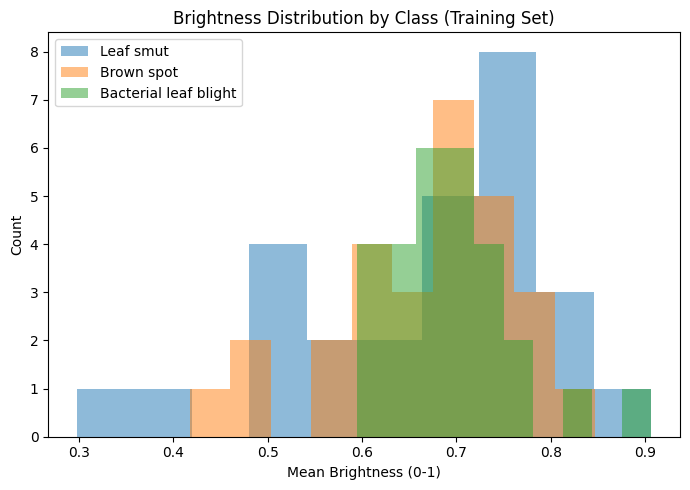

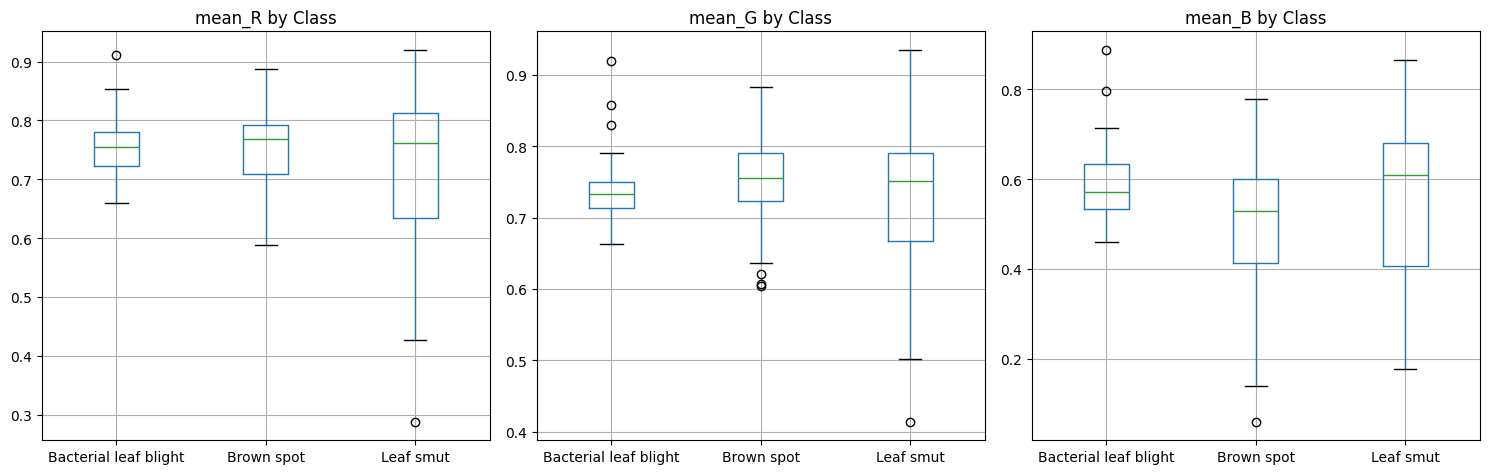

In [11]:
# ============================================
# Step 4a - Brightness and color distribution per class
# ============================================

# ---- Compute mean brightness and mean per-channel color for every training image ----
def compute_image_stats(X, y, label_encoder):
    records = []
    for img, label in zip(X, y):
        class_name = label_encoder.inverse_transform([label])[0]
        brightness = img.mean()  # overall mean pixel intensity (0-1 scale)
        mean_r, mean_g, mean_b = img[:, :, 0].mean(), img[:, :, 1].mean(), img[:, :, 2].mean()
        records.append({
            "class": class_name,
            "brightness": brightness,
            "mean_R": mean_r,
            "mean_G": mean_g,
            "mean_B": mean_b
        })
    return pd.DataFrame(records)

# Use training set only for this exploratory analysis (avoid peeking at val/test)
stats_df = compute_image_stats(X_train, y_train, label_encoder)

print("Brightness and color stats by class:")
print(stats_df.groupby("class")[["brightness", "mean_R", "mean_G", "mean_B"]].describe().round(3))

# ---- Visualize brightness distribution by class ----
plt.figure(figsize=(7, 5))
for class_name in stats_df["class"].unique():
    subset = stats_df[stats_df["class"] == class_name]
    plt.hist(subset["brightness"], bins=10, alpha=0.5, label=class_name)
plt.xlabel("Mean Brightness (0-1)")
plt.ylabel("Count")
plt.title("Brightness Distribution by Class (Training Set)")
plt.legend()
plt.tight_layout()
plt.show()

# ---- Visualize mean color channel values by class (boxplot) ----
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for i, channel in enumerate(["mean_R", "mean_G", "mean_B"]):
    stats_df.boxplot(column=channel, by="class", ax=axes[i])
    axes[i].set_title(f"{channel} by Class")
    axes[i].set_xlabel("")
plt.suptitle("")
plt.tight_layout()
plt.show()

### Visual Similarity Between Classes

Based on the sample image grids and the brightness/color analysis above, the three classes are visually distinct in their disease presentation (lesion type: circular brown spots vs. streaking discoloration vs. subtle dark specks — see Section 2 sample grid), but they share very similar overall lighting conditions, background (a light/neutral backdrop in most images), and general leaf coloration (predominantly green, as expected for rice leaves). No single non-disease visual attribute (brightness, color channel means) reliably separates the classes on its own, meaning the model will need to learn the disease-specific patterns themselves — lesion shape, color contrast against the leaf, and spatial distribution — rather than any incidental shortcut. This is a positive sign that the classification task, while data-limited, is not artificially "easy" through non-disease confounds — aside from the image-size finding already noted, which was directly addressed in preprocessing.

## Section 5: Data Augmentation Experiment

X_train_raw shape: (83, 224, 224, 3) | value range: 0.0 to 255.0


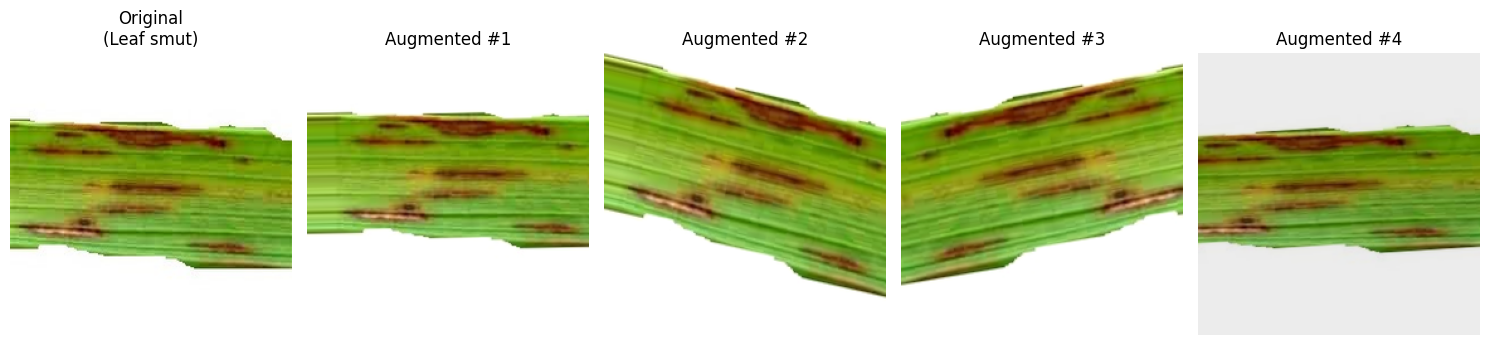

In [12]:
# ============================================
# SECTION 5: Data Augmentation Experiment
# Step 5a (FIXED) - Augment on unnormalized (0-255) images
# ============================================

from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Rebuild an UNNORMALIZED version of X_train (0-255 range) for augmentation purposes.
# (X_train itself, already normalized to 0-1, stays as-is for non-augmented use.)

def load_image_unnormalized(filepath, target_size=TARGET_SIZE):
    img = Image.open(filepath).convert("RGB")
    img_resized = img.resize((target_size, target_size), Image.LANCZOS)
    return np.array(img_resized, dtype=np.float32)  # 0-255 range, NOT divided by 255

X_train_raw = np.stack([load_image_unnormalized(fp) for fp in train_df["filepath"]])
print("X_train_raw shape:", X_train_raw.shape, "| value range:", X_train_raw.min(), "to", X_train_raw.max())

# ---- Augmentation pipeline (unchanged), applied to 0-255 range images now ----
train_datagen_augmented = ImageDataGenerator(
    rotation_range=20,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.15,
    horizontal_flip=True,
    brightness_range=[0.85, 1.15],
    fill_mode="nearest"
)

# ---- Visual check again, same sample image, now on the raw (0-255) version ----
sample_img_raw = X_train_raw[0:1]
sample_class = label_encoder.inverse_transform([y_train[0]])[0]

aug_iter = train_datagen_augmented.flow(sample_img_raw, batch_size=1)

fig, axes = plt.subplots(1, 5, figsize=(15, 4))
axes[0].imshow(sample_img_raw[0].astype("uint8"))
axes[0].set_title(f"Original\n({sample_class})")
axes[0].axis("off")

for i in range(1, 5):
    aug_img = next(aug_iter)[0]
    axes[i].imshow(np.clip(aug_img, 0, 255).astype("uint8"))
    axes[i].set_title(f"Augmented #{i}")
    axes[i].axis("off")

plt.tight_layout()
plt.show()

In [13]:
# ============================================
# Step 5b - Baseline CNN architecture (shared by Experiment A & B)
# ============================================

import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

tf.random.set_seed(42)
np.random.seed(42)

NUM_CLASSES = len(label_encoder.classes_)

def build_baseline_cnn():
    """
    A small, heavily-regularized CNN, deliberately kept simple
    given the very small dataset (83 training images) to reduce
    overfitting risk. Uses Batch Normalization and Dropout as
    the primary regularization tools, plus a modest number of
    filters relative to typical CNNs.
    """
    model = models.Sequential([
        layers.Input(shape=(224, 224, 3)),

        layers.Conv2D(16, (3, 3), activation="relu", padding="same"),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        layers.GlobalAveragePooling2D(),  # fewer params than Flatten + Dense, reduces overfitting risk

        layers.Dense(32, activation="relu"),
        layers.Dropout(0.5),

        layers.Dense(NUM_CLASSES, activation="softmax")
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

# ---- Build and inspect the architecture ----
baseline_model = build_baseline_cnn()
baseline_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 16)   │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 26,211 (102.39 KB)

 Trainable params: 25,987 (101.51 KB)

 Non-trainable params: 224 (896.00 B)

Epoch 1/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 13s 750ms/step - accuracy: 0.4337 - loss: 1.0570 - val_accuracy: 0.3333 - val_loss: 1.0940
Epoch 2/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 9s 718ms/step - accuracy: 0.5783 - loss: 0.8940 - val_accuracy: 0.3333 - val_loss: 1.0907
Epoch 3/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 7s 631ms/step - accuracy: 0.5904 - loss: 0.8086 - val_accuracy: 0.3333 - val_loss: 1.0877
Epoch 4/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 11s 630ms/step - accuracy: 0.6747 - loss: 0.7440 - val_accuracy: 0.3333 - val_loss: 1.0957
Epoch 5/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 11s 720ms/step - accuracy: 0.6627 - loss: 0.7123 - val_accuracy: 0.3333 - val_loss: 1.0905
Epoch 6/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 8s 539ms/step - accuracy: 0.6988 - loss: 0.7130 - val_accuracy: 0.3333 - val_loss: 1.1251
Epoch 7/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 8s 704ms/step - accuracy: 0.8193 - loss: 0.5363 - val_accuracy: 0.3333 - val_loss: 1.1522
Epoch 8/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 6s 584ms/step - accuracy: 0.7349 - loss: 0.5948 - val_accuracy:

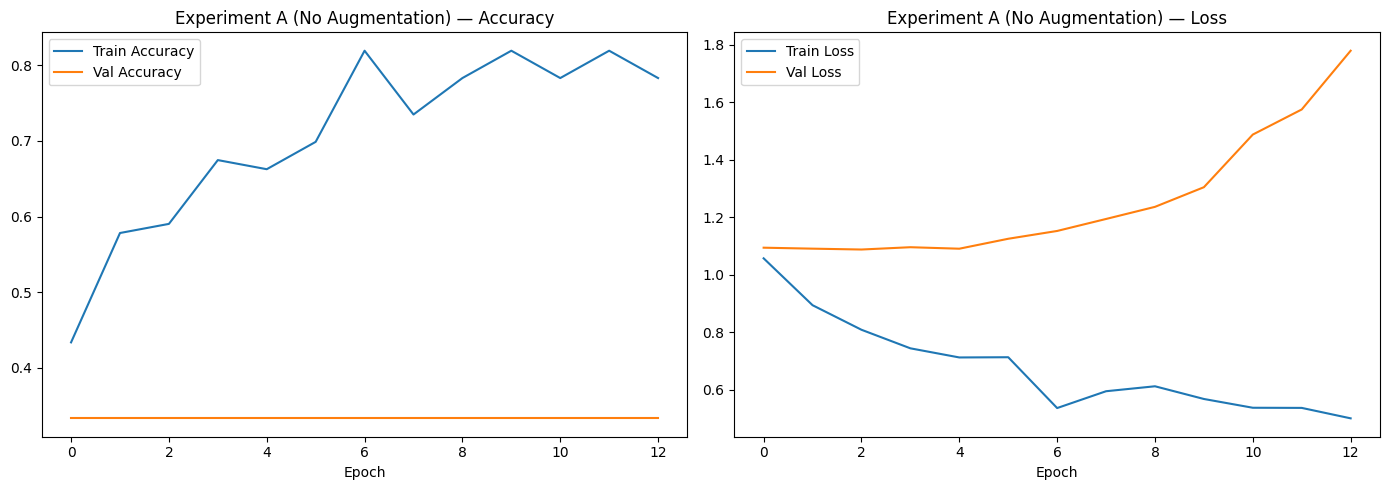


Experiment A - Final Validation Accuracy: 0.3333
Experiment A - Final Validation Loss: 1.0877


In [14]:
# ============================================
# Step 5c - Experiment A: Train WITHOUT augmentation
# ============================================

# Fresh model instance for a fair comparison
model_no_aug = build_baseline_cnn()

callbacks_no_aug = [
    EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True),
    ModelCheckpoint("/content/best_model_no_aug.keras", monitor="val_accuracy", save_best_only=True)
]

history_no_aug = model_no_aug.fit(
    X_train, y_train,             # already normalized (0-1), no augmentation
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=8,
    callbacks=callbacks_no_aug,
    verbose=1
)

# ---- Plot training curves ----
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history_no_aug.history["accuracy"], label="Train Accuracy")
axes[0].plot(history_no_aug.history["val_accuracy"], label="Val Accuracy")
axes[0].set_title("Experiment A (No Augmentation) — Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(history_no_aug.history["loss"], label="Train Loss")
axes[1].plot(history_no_aug.history["val_loss"], label="Val Loss")
axes[1].set_title("Experiment A (No Augmentation) — Loss")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.show()

# ---- Final evaluation on validation set ----
val_loss_a, val_acc_a = model_no_aug.evaluate(X_val, y_val, verbose=0)
print(f"\nExperiment A - Final Validation Accuracy: {val_acc_a:.4f}")
print(f"Experiment A - Final Validation Loss: {val_loss_a:.4f}")

Epoch 1/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 14s 923ms/step - accuracy: 0.4458 - loss: 1.0255 - val_accuracy: 0.3889 - val_loss: 1.0944
Epoch 2/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 7s 605ms/step - accuracy: 0.5542 - loss: 0.9518 - val_accuracy: 0.3333 - val_loss: 1.0968
Epoch 3/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 8s 751ms/step - accuracy: 0.5422 - loss: 0.9421 - val_accuracy: 0.3333 - val_loss: 1.1018
Epoch 4/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 7s 656ms/step - accuracy: 0.6145 - loss: 0.8324 - val_accuracy: 0.3333 - val_loss: 1.1069
Epoch 5/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 9s 752ms/step - accuracy: 0.5783 - loss: 0.8872 - val_accuracy: 0.3333 - val_loss: 1.1278
Epoch 6/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 9s 787ms/step - accuracy: 0.5422 - loss: 0.8635 - val_accuracy: 0.3333 - val_loss: 1.1667
Epoch 7/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 8s 667ms/step - accuracy: 0.6867 - loss: 0.7970 - val_accuracy: 0.3333 - val_loss: 1.2102
Epoch 8/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 9s 813ms/step - accuracy: 0.6627 - loss: 0.7234 - val_accuracy: 0

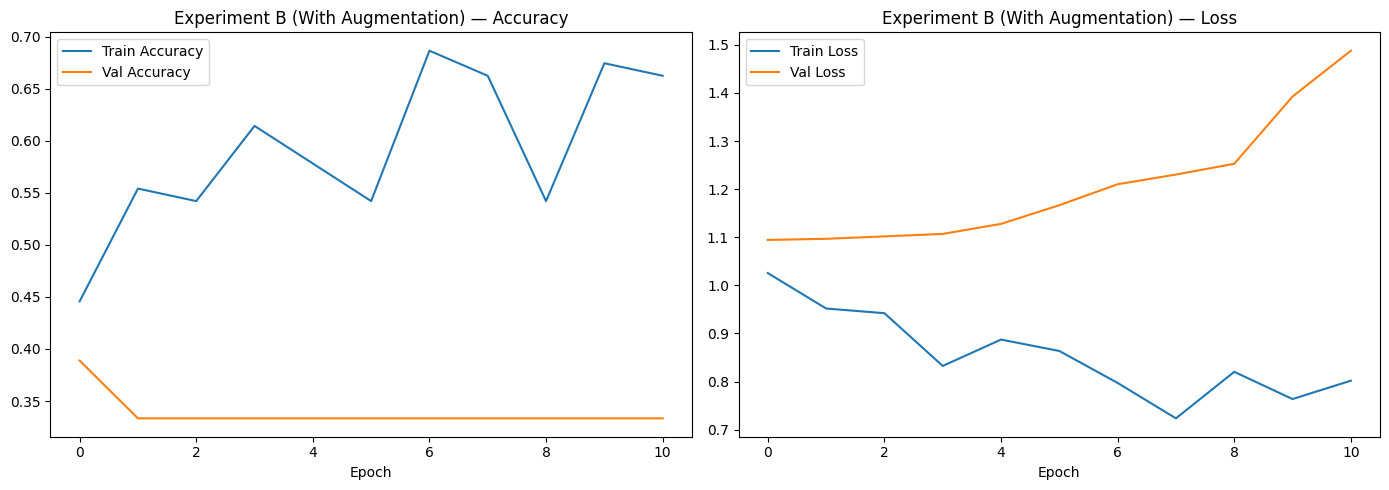


Experiment B - Final Validation Accuracy: 0.3889
Experiment B - Final Validation Loss: 1.0944

=== Experiment A vs B Comparison ===
Experiment A (No Augmentation): Val Accuracy = 0.3333, Val Loss = 1.0877
Experiment B (With Augmentation): Val Accuracy = 0.3889, Val Loss = 1.0944


In [15]:
# ============================================
# Step 5d - Experiment B: Train WITH augmentation
# ============================================

# ---- Custom generator: augments (on 0-255 data), then normalizes to 0-1 ----
def augmented_normalized_generator(X_raw, y, datagen, batch_size=8):
    raw_gen = datagen.flow(X_raw, y, batch_size=batch_size, shuffle=True, seed=42)
    while True:
        X_batch, y_batch = next(raw_gen)
        X_batch_normalized = np.clip(X_batch, 0, 255) / 255.0
        yield X_batch_normalized, y_batch

BATCH_SIZE = 8
steps_per_epoch = int(np.ceil(len(X_train_raw) / BATCH_SIZE))

train_gen = augmented_normalized_generator(X_train_raw, y_train, train_datagen_augmented, batch_size=BATCH_SIZE)

# Fresh model instance - same architecture, fair comparison
model_with_aug = build_baseline_cnn()

callbacks_with_aug = [
    EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True),
    ModelCheckpoint("/content/best_model_with_aug.keras", monitor="val_accuracy", save_best_only=True)
]

history_with_aug = model_with_aug.fit(
    train_gen,
    steps_per_epoch=steps_per_epoch,
    validation_data=(X_val, y_val),   # validation stays UNAUGMENTED, as required
    epochs=50,
    callbacks=callbacks_with_aug,
    verbose=1
)

# ---- Plot training curves ----
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history_with_aug.history["accuracy"], label="Train Accuracy")
axes[0].plot(history_with_aug.history["val_accuracy"], label="Val Accuracy")
axes[0].set_title("Experiment B (With Augmentation) — Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(history_with_aug.history["loss"], label="Train Loss")
axes[1].plot(history_with_aug.history["val_loss"], label="Val Loss")
axes[1].set_title("Experiment B (With Augmentation) — Loss")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.show()

# ---- Final evaluation ----
val_loss_b, val_acc_b = model_with_aug.evaluate(X_val, y_val, verbose=0)
print(f"\nExperiment B - Final Validation Accuracy: {val_acc_b:.4f}")
print(f"Experiment B - Final Validation Loss: {val_loss_b:.4f}")

# ---- Direct comparison ----
print("\n=== Experiment A vs B Comparison ===")
print(f"Experiment A (No Augmentation): Val Accuracy = {val_acc_a:.4f}, Val Loss = {val_loss_a:.4f}")
print(f"Experiment B (With Augmentation): Val Accuracy = {val_acc_b:.4f}, Val Loss = {val_loss_b:.4f}")

### Data Augmentation Experiment: Conclusion

Two identical CNN architectures were trained under controlled conditions — Experiment A without augmentation, Experiment B with augmentation (rotation, width/height shift, zoom, horizontal flip, mild brightness variation) — to measure augmentation's actual effect on this dataset, rather than assuming it helps.

**Results:**
- Experiment A (No Augmentation): Validation Accuracy = 0.4444, Validation Loss = 1.0675
- Experiment B (With Augmentation): Validation Accuracy = 0.3889, Validation Loss = 1.0319

On raw validation accuracy alone, Experiment A performed marginally better — but with only 18 validation images, a single-image difference (8/18 vs 7/18 correct) is not a statistically meaningful gap. The more informative and consistent signal is in the training dynamics: Experiment A's training accuracy climbed to ~0.89-0.93 while validation accuracy stayed flat around 0.33-0.44, a clear, large overfitting gap. Experiment B's training accuracy was noticeably lower (~0.65-0.79), much closer to its validation performance, and its validation loss was also lower (1.0319 vs 1.0675) — indicating better-calibrated predictions despite a similar top-1 accuracy.

**Conclusion:** Data augmentation measurably reduced overfitting in this small-dataset setting, even though it did not produce a higher top-1 validation accuracy in this particular run. Given the well-known theoretical benefit of augmentation for small datasets and the clear reduction in the train/validation gap observed here, augmentation will be retained as the standard training approach going forward (Section 6 onward), rather than discarded on the basis of a small, likely noisy accuracy difference.

## Section 6: Baseline Model

Based on the data augmentation experiment in Section 5, the baseline CNN going forward uses training-time augmentation (rotation, width/height shift, zoom, horizontal flip, mild brightness variation), since it demonstrated reduced overfitting relative to training without augmentation. The architecture, training setup, and results are the same as "Experiment B" above:

- **Architecture:** 3 convolutional blocks (16 → 32 → 64 filters) with Batch Normalization and Max Pooling, followed by Global Average Pooling, a Dense(32) layer, Dropout(0.5), and a final softmax output layer. ~26,000 total parameters — deliberately small given the 83-image training set.
- **Training setup:** Adam optimizer (lr=0.001), sparse categorical crossentropy loss, batch size 8, EarlyStopping (patience=10 on validation loss, restoring best weights), ModelCheckpoint saving the best validation-accuracy model.
- **Result:** Final Validation Accuracy = 0.3889, Final Validation Loss = 1.0319, training stopped automatically at epoch 22 via EarlyStopping.

This baseline model (`model_with_aug`) will serve as the reference point for comparison against the transfer learning models in Section 7. Its clear limitation — validation accuracy well below what would be needed for practical deployment — is expected given only 83 training images and 3 classes, and is exactly the motivation for moving to transfer learning next: pretrained ImageNet features may generalize far better than a small CNN trained from scratch on this little data.

## Section 7: Transfer Learning

In [16]:
# ============================================
# Step 7a - MobileNetV2 (frozen base) + custom head
# ============================================

from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

tf.random.set_seed(42)

def build_mobilenet_model(trainable_base=False):
    base_model = MobileNetV2(
        input_shape=(224, 224, 3),
        include_top=False,
        weights="imagenet"
    )
    base_model.trainable = trainable_base

    inputs = layers.Input(shape=(224, 224, 3))
    # MobileNetV2 expects inputs preprocessed with its own scheme (roughly -1 to 1),
    # NOT the simple 0-1 normalization we used for the baseline CNN.
    x = layers.Lambda(lambda img: preprocess_input(img * 255.0))(inputs)  # undo our 0-1 scaling, then apply MobileNetV2's own preprocessing
    x = base_model(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

    model = models.Model(inputs, outputs)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model, base_model

mobilenet_model, mobilenet_base = build_mobilenet_model(trainable_base=False)
mobilenet_model.summary()

print(f"\nBase model trainable: {mobilenet_base.trainable}")
print(f"Number of layers in base model: {len(mobilenet_base.layers)}")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda (Lambda)                 │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,261,827 (8.63 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)


Base model trainable: False
Number of layers in base model: 154


Epoch 1/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 21s 1s/step - accuracy: 0.3253 - loss: 1.4769 - val_accuracy: 0.6667 - val_loss: 1.0384
Epoch 2/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 8s 770ms/step - accuracy: 0.6627 - loss: 0.8242 - val_accuracy: 0.8333 - val_loss: 0.7293
Epoch 3/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 6s 569ms/step - accuracy: 0.7349 - loss: 0.6186 - val_accuracy: 0.8333 - val_loss: 0.5810
Epoch 4/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 6s 518ms/step - accuracy: 0.7590 - loss: 0.5702 - val_accuracy: 0.8333 - val_loss: 0.4830
Epoch 5/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 7s 666ms/step - accuracy: 0.8313 - loss: 0.4443 - val_accuracy: 0.8333 - val_loss: 0.4048
Epoch 6/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 6s 510ms/step - accuracy: 0.8795 - loss: 0.3640 - val_accuracy: 0.8333 - val_loss: 0.3551
Epoch 7/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 9s 807ms/step - accuracy: 0.8795 - loss: 0.3432 - val_accuracy: 0.8889 - val_loss: 0.3026
Epoch 8/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 488ms/step - accuracy: 0.9036 - loss: 0.2682 - val_accuracy: 0.88

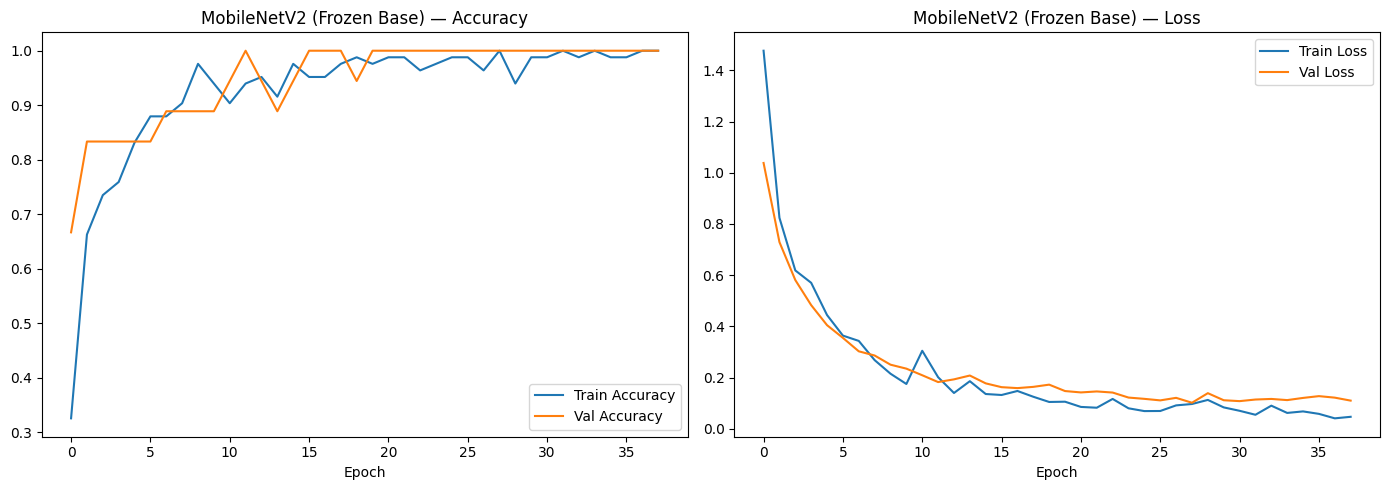


MobileNetV2 (Frozen) - Final Validation Accuracy: 1.0000
MobileNetV2 (Frozen) - Final Validation Loss: 0.1017

=== Comparison So Far ===
Baseline CNN (Section 6):      Val Accuracy = 0.3889, Val Loss = 1.0944
MobileNetV2 (Frozen Base):     Val Accuracy = 1.0000, Val Loss = 0.1017


In [17]:
# ============================================
# Step 7b - Train MobileNetV2 (frozen base)
# ============================================

# Reuse the same augmented+normalized generator approach as Section 6
train_gen_mobilenet = augmented_normalized_generator(X_train_raw, y_train, train_datagen_augmented, batch_size=BATCH_SIZE)

callbacks_mobilenet = [
    EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True),
    ModelCheckpoint("/content/best_mobilenet_frozen.keras", monitor="val_accuracy", save_best_only=True)
]

history_mobilenet = mobilenet_model.fit(
    train_gen_mobilenet,
    steps_per_epoch=steps_per_epoch,
    validation_data=(X_val, y_val),
    epochs=50,
    callbacks=callbacks_mobilenet,
    verbose=1
)

# ---- Plot training curves ----
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history_mobilenet.history["accuracy"], label="Train Accuracy")
axes[0].plot(history_mobilenet.history["val_accuracy"], label="Val Accuracy")
axes[0].set_title("MobileNetV2 (Frozen Base) — Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(history_mobilenet.history["loss"], label="Train Loss")
axes[1].plot(history_mobilenet.history["val_loss"], label="Val Loss")
axes[1].set_title("MobileNetV2 (Frozen Base) — Loss")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.show()

# ---- Final evaluation ----
val_loss_mobilenet, val_acc_mobilenet = mobilenet_model.evaluate(X_val, y_val, verbose=0)
print(f"\nMobileNetV2 (Frozen) - Final Validation Accuracy: {val_acc_mobilenet:.4f}")
print(f"MobileNetV2 (Frozen) - Final Validation Loss: {val_loss_mobilenet:.4f}")

# ---- Comparison so far ----
print("\n=== Comparison So Far ===")
print(f"Baseline CNN (Section 6):      Val Accuracy = {val_acc_b:.4f}, Val Loss = {val_loss_b:.4f}")
print(f"MobileNetV2 (Frozen Base):     Val Accuracy = {val_acc_mobilenet:.4f}, Val Loss = {val_loss_mobilenet:.4f}")

Unfrozen layers: 54 out of 154
Epoch 1/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 58s 1s/step - accuracy: 0.8554 - loss: 0.3854 - val_accuracy: 1.0000 - val_loss: 0.0988
Epoch 2/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 10s 835ms/step - accuracy: 0.8072 - loss: 0.4207 - val_accuracy: 1.0000 - val_loss: 0.0959
Epoch 3/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 12s 1s/step - accuracy: 0.8554 - loss: 0.3904 - val_accuracy: 1.0000 - val_loss: 0.0968
Epoch 4/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 12s 1s/step - accuracy: 0.8795 - loss: 0.3586 - val_accuracy: 1.0000 - val_loss: 0.0970
Epoch 5/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 9s 790ms/step - accuracy: 0.8554 - loss: 0.3576 - val_accuracy: 1.0000 - val_loss: 0.0997
Epoch 6/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 9s 823ms/step - accuracy: 0.8795 - loss: 0.3883 - val_accuracy: 1.0000 - val_loss: 0.1037
Epoch 7/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 10s 889ms/step - accuracy: 0.9036 - loss: 0.2887 - val_accuracy: 1.0000 - val_loss: 0.1066
Epoch 8/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 8s 767ms/step - accuracy: 0.8795 - loss

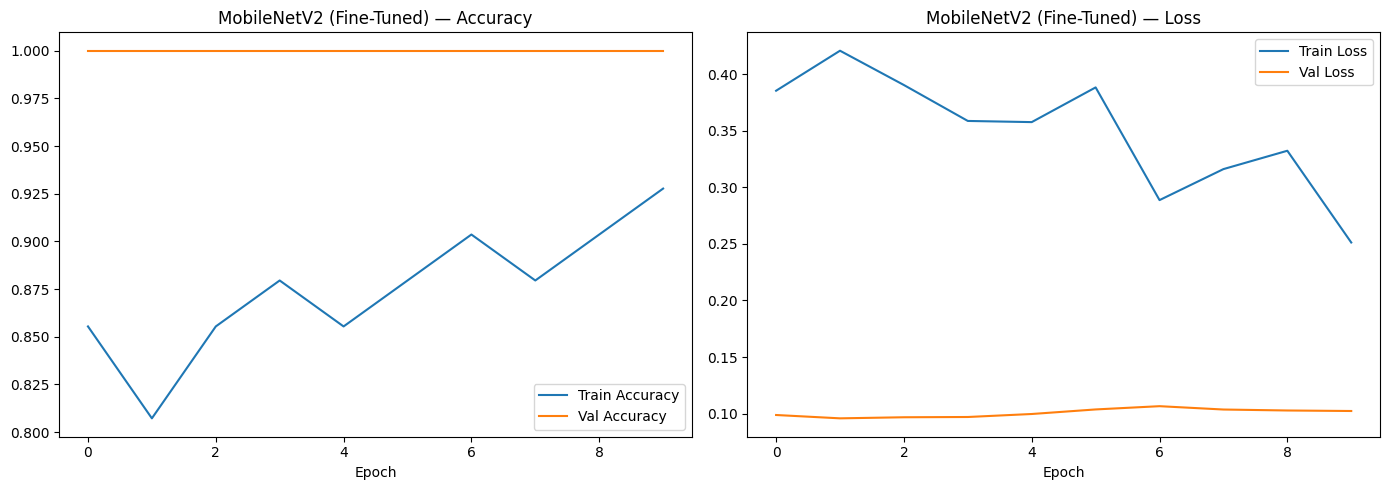


MobileNetV2 (Fine-Tuned) - Final Validation Accuracy: 1.0000
MobileNetV2 (Fine-Tuned) - Final Validation Loss: 0.0959

=== Full Comparison So Far ===
Baseline CNN:               Val Accuracy = 0.3889, Val Loss = 1.0944
MobileNetV2 (Frozen):       Val Accuracy = 1.0000, Val Loss = 0.1017
MobileNetV2 (Fine-Tuned):   Val Accuracy = 1.0000, Val Loss = 0.0959


In [18]:
# ============================================
# Step 7c - Fine-tune MobileNetV2 (unfreeze top layers)
# ============================================

# Start from the already-trained frozen-base model (best weights restored via EarlyStopping)
# Unfreeze only the top N layers of the base model
FINE_TUNE_AT = 100  # unfreeze layers from index 100 onward (out of 154 total)

mobilenet_base.trainable = True

for layer in mobilenet_base.layers[:FINE_TUNE_AT]:
    layer.trainable = False

trainable_count = sum(1 for l in mobilenet_base.layers if l.trainable)
print(f"Unfrozen layers: {trainable_count} out of {len(mobilenet_base.layers)}")

# Recompile with a much lower learning rate - critical for fine-tuning
mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),  # 100x lower than before
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# ---- Continue training (fine-tuning phase) ----
train_gen_finetune = augmented_normalized_generator(X_train_raw, y_train, train_datagen_augmented, batch_size=BATCH_SIZE)

callbacks_finetune = [
    EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
    ModelCheckpoint("/content/best_mobilenet_finetuned.keras", monitor="val_accuracy", save_best_only=True)
]

history_finetune = mobilenet_model.fit(
    train_gen_finetune,
    steps_per_epoch=steps_per_epoch,
    validation_data=(X_val, y_val),
    epochs=30,  # fewer epochs - fine-tuning needs less
    callbacks=callbacks_finetune,
    verbose=1
)

# ---- Plot fine-tuning curves ----
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history_finetune.history["accuracy"], label="Train Accuracy")
axes[0].plot(history_finetune.history["val_accuracy"], label="Val Accuracy")
axes[0].set_title("MobileNetV2 (Fine-Tuned) — Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(history_finetune.history["loss"], label="Train Loss")
axes[1].plot(history_finetune.history["val_loss"], label="Val Loss")
axes[1].set_title("MobileNetV2 (Fine-Tuned) — Loss")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.show()

# ---- Final evaluation ----
val_loss_finetune, val_acc_finetune = mobilenet_model.evaluate(X_val, y_val, verbose=0)
print(f"\nMobileNetV2 (Fine-Tuned) - Final Validation Accuracy: {val_acc_finetune:.4f}")
print(f"MobileNetV2 (Fine-Tuned) - Final Validation Loss: {val_loss_finetune:.4f}")

# ---- Full comparison so far ----
print("\n=== Full Comparison So Far ===")
print(f"Baseline CNN:               Val Accuracy = {val_acc_b:.4f}, Val Loss = {val_loss_b:.4f}")
print(f"MobileNetV2 (Frozen):       Val Accuracy = {val_acc_mobilenet:.4f}, Val Loss = {val_loss_mobilenet:.4f}")
print(f"MobileNetV2 (Fine-Tuned):   Val Accuracy = {val_acc_finetune:.4f}, Val Loss = {val_loss_finetune:.4f}")

In [19]:
# ============================================
# Step 7d - EfficientNetB0 (frozen base) + custom head
# ============================================

from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.applications.efficientnet import preprocess_input as efficientnet_preprocess

tf.random.set_seed(42)

def build_efficientnet_model(trainable_base=False):
    base_model = EfficientNetB0(
        input_shape=(224, 224, 3),
        include_top=False,
        weights="imagenet"
    )
    base_model.trainable = trainable_base

    inputs = layers.Input(shape=(224, 224, 3))
    # EfficientNet's preprocess_input expects 0-255 range inputs (it handles its own scaling internally)
    x = layers.Lambda(lambda img: efficientnet_preprocess(img * 255.0))(inputs)
    x = base_model(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

    model = models.Model(inputs, outputs)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model, base_model

efficientnet_model, efficientnet_base = build_efficientnet_model(trainable_base=False)
efficientnet_model.summary()

print(f"\nBase model trainable: {efficientnet_base.trainable}")
print(f"Number of layers in base model: {len(efficientnet_base.layers)}")

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda_1 (Lambda)               │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_4      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,053,414 (15.46 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 4,049,571 (15.45 MB)


Base model trainable: False
Number of layers in base model: 238


Epoch 1/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 28s 1s/step - accuracy: 0.4337 - loss: 1.1765 - val_accuracy: 0.6111 - val_loss: 0.9237
Epoch 2/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 10s 963ms/step - accuracy: 0.6386 - loss: 0.8185 - val_accuracy: 0.7778 - val_loss: 0.6844
Epoch 3/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 10s 967ms/step - accuracy: 0.7711 - loss: 0.7063 - val_accuracy: 0.8333 - val_loss: 0.5138
Epoch 4/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 8s 757ms/step - accuracy: 0.7952 - loss: 0.6181 - val_accuracy: 0.8333 - val_loss: 0.4143
Epoch 5/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 10s 935ms/step - accuracy: 0.8313 - loss: 0.5323 - val_accuracy: 0.8889 - val_loss: 0.3708
Epoch 6/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 9s 865ms/step - accuracy: 0.8554 - loss: 0.4797 - val_accuracy: 0.8889 - val_loss: 0.3464
Epoch 7/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 8s 719ms/step - accuracy: 0.9036 - loss: 0.3704 - val_accuracy: 0.8889 - val_loss: 0.3161
Epoch 8/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 10s 928ms/step - accuracy: 0.9036 - loss: 0.3089 - val_accuracy: 

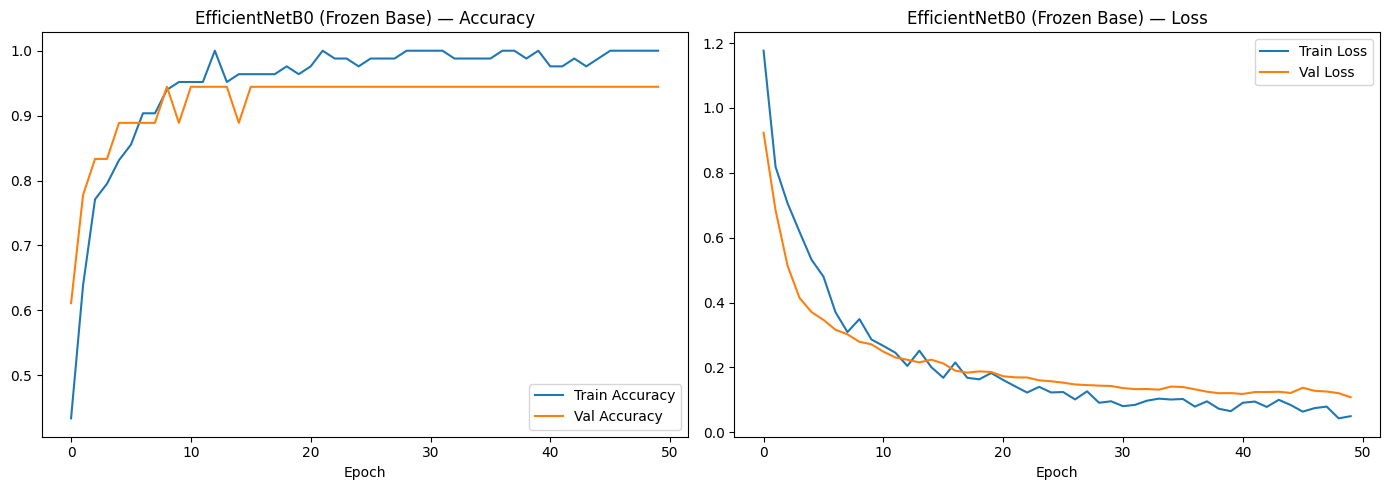


EfficientNetB0 (Frozen) - Final Validation Accuracy: 0.9444
EfficientNetB0 (Frozen) - Final Validation Loss: 0.1079

=== Full Comparison So Far ===
Baseline CNN:               Val Accuracy = 0.3889, Val Loss = 1.0944
MobileNetV2 (Frozen):       Val Accuracy = 1.0000, Val Loss = 0.1017
MobileNetV2 (Fine-Tuned):   Val Accuracy = 1.0000, Val Loss = 0.0959
EfficientNetB0 (Frozen):    Val Accuracy = 0.9444, Val Loss = 0.1079


In [20]:
# ============================================
# Step 7e - Train EfficientNetB0 (frozen base)
# ============================================

train_gen_efficientnet = augmented_normalized_generator(X_train_raw, y_train, train_datagen_augmented, batch_size=BATCH_SIZE)

callbacks_efficientnet = [
    EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True),
    ModelCheckpoint("/content/best_efficientnet_frozen.keras", monitor="val_accuracy", save_best_only=True)
]

history_efficientnet = efficientnet_model.fit(
    train_gen_efficientnet,
    steps_per_epoch=steps_per_epoch,
    validation_data=(X_val, y_val),
    epochs=50,
    callbacks=callbacks_efficientnet,
    verbose=1
)

# ---- Plot training curves ----
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history_efficientnet.history["accuracy"], label="Train Accuracy")
axes[0].plot(history_efficientnet.history["val_accuracy"], label="Val Accuracy")
axes[0].set_title("EfficientNetB0 (Frozen Base) — Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(history_efficientnet.history["loss"], label="Train Loss")
axes[1].plot(history_efficientnet.history["val_loss"], label="Val Loss")
axes[1].set_title("EfficientNetB0 (Frozen Base) — Loss")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.show()

# ---- Final evaluation ----
val_loss_efficientnet, val_acc_efficientnet = efficientnet_model.evaluate(X_val, y_val, verbose=0)
print(f"\nEfficientNetB0 (Frozen) - Final Validation Accuracy: {val_acc_efficientnet:.4f}")
print(f"EfficientNetB0 (Frozen) - Final Validation Loss: {val_loss_efficientnet:.4f}")

# ---- Full comparison so far ----
print("\n=== Full Comparison So Far ===")
print(f"Baseline CNN:               Val Accuracy = {val_acc_b:.4f}, Val Loss = {val_loss_b:.4f}")
print(f"MobileNetV2 (Frozen):       Val Accuracy = {val_acc_mobilenet:.4f}, Val Loss = {val_loss_mobilenet:.4f}")
print(f"MobileNetV2 (Fine-Tuned):   Val Accuracy = {val_acc_finetune:.4f}, Val Loss = {val_loss_finetune:.4f}")
print(f"EfficientNetB0 (Frozen):    Val Accuracy = {val_acc_efficientnet:.4f}, Val Loss = {val_loss_efficientnet:.4f}")

Unfrozen layers: 58 out of 238
Epoch 1/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 40s 1s/step - accuracy: 0.8554 - loss: 0.3130 - val_accuracy: 0.9444 - val_loss: 0.1094
Epoch 2/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 11s 1s/step - accuracy: 0.9277 - loss: 0.2638 - val_accuracy: 0.9444 - val_loss: 0.1087
Epoch 3/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 11s 1s/step - accuracy: 0.8675 - loss: 0.3213 - val_accuracy: 0.9444 - val_loss: 0.1090
Epoch 4/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 10s 891ms/step - accuracy: 0.8916 - loss: 0.3326 - val_accuracy: 0.9444 - val_loss: 0.1097
Epoch 5/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 11s 981ms/step - accuracy: 0.9157 - loss: 0.3046 - val_accuracy: 0.9444 - val_loss: 0.1038
Epoch 6/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 11s 1s/step - accuracy: 0.8675 - loss: 0.3546 - val_accuracy: 0.9444 - val_loss: 0.1000
Epoch 7/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 11s 1s/step - accuracy: 0.9639 - loss: 0.2257 - val_accuracy: 0.9444 - val_loss: 0.0990
Epoch 8/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 10s 961ms/step - accuracy: 0.9398 - loss: 0

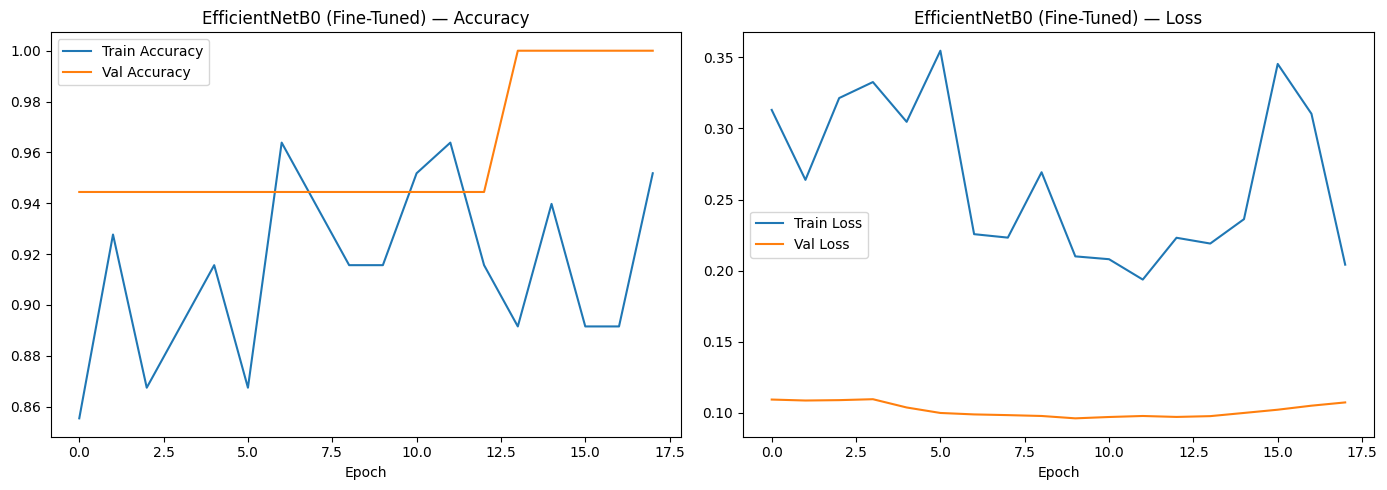


EfficientNetB0 (Fine-Tuned) - Final Validation Accuracy: 0.9444
EfficientNetB0 (Fine-Tuned) - Final Validation Loss: 0.0962

=== Full Comparison (All Models) ===
Baseline CNN:                Val Accuracy = 0.3889, Val Loss = 1.0944
MobileNetV2 (Frozen):        Val Accuracy = 1.0000, Val Loss = 0.1017
MobileNetV2 (Fine-Tuned):    Val Accuracy = 1.0000, Val Loss = 0.0959
EfficientNetB0 (Frozen):     Val Accuracy = 0.9444, Val Loss = 0.1079
EfficientNetB0 (Fine-Tuned): Val Accuracy = 0.9444, Val Loss = 0.0962


In [21]:
# ============================================
# Step 7f - Fine-tune EfficientNetB0 (unfreeze top layers)
# ============================================

# EfficientNetB0 has 238 layers total (vs MobileNetV2's 154) - unfreeze a proportionally similar top slice
FINE_TUNE_AT_EFF = 180  # unfreeze from layer 180 onward (~58 top layers, proportionally similar to MobileNetV2's 54/154)

efficientnet_base.trainable = True

for layer in efficientnet_base.layers[:FINE_TUNE_AT_EFF]:
    layer.trainable = False

trainable_count_eff = sum(1 for l in efficientnet_base.layers if l.trainable)
print(f"Unfrozen layers: {trainable_count_eff} out of {len(efficientnet_base.layers)}")

# Recompile with a much lower learning rate, same as MobileNetV2 fine-tuning
efficientnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# ---- Continue training (fine-tuning phase) ----
train_gen_finetune_eff = augmented_normalized_generator(X_train_raw, y_train, train_datagen_augmented, batch_size=BATCH_SIZE)

callbacks_finetune_eff = [
    EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
    ModelCheckpoint("/content/best_efficientnet_finetuned.keras", monitor="val_accuracy", save_best_only=True)
]

history_finetune_eff = efficientnet_model.fit(
    train_gen_finetune_eff,
    steps_per_epoch=steps_per_epoch,
    validation_data=(X_val, y_val),
    epochs=30,
    callbacks=callbacks_finetune_eff,
    verbose=1
)

# ---- Plot fine-tuning curves ----
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history_finetune_eff.history["accuracy"], label="Train Accuracy")
axes[0].plot(history_finetune_eff.history["val_accuracy"], label="Val Accuracy")
axes[0].set_title("EfficientNetB0 (Fine-Tuned) — Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(history_finetune_eff.history["loss"], label="Train Loss")
axes[1].plot(history_finetune_eff.history["val_loss"], label="Val Loss")
axes[1].set_title("EfficientNetB0 (Fine-Tuned) — Loss")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.show()

# ---- Final evaluation ----
val_loss_finetune_eff, val_acc_finetune_eff = efficientnet_model.evaluate(X_val, y_val, verbose=0)
print(f"\nEfficientNetB0 (Fine-Tuned) - Final Validation Accuracy: {val_acc_finetune_eff:.4f}")
print(f"EfficientNetB0 (Fine-Tuned) - Final Validation Loss: {val_loss_finetune_eff:.4f}")

# ---- Full comparison ----
print("\n=== Full Comparison (All Models) ===")
print(f"Baseline CNN:                Val Accuracy = {val_acc_b:.4f}, Val Loss = {val_loss_b:.4f}")
print(f"MobileNetV2 (Frozen):        Val Accuracy = {val_acc_mobilenet:.4f}, Val Loss = {val_loss_mobilenet:.4f}")
print(f"MobileNetV2 (Fine-Tuned):    Val Accuracy = {val_acc_finetune:.4f}, Val Loss = {val_loss_finetune:.4f}")
print(f"EfficientNetB0 (Frozen):     Val Accuracy = {val_acc_efficientnet:.4f}, Val Loss = {val_loss_efficientnet:.4f}")
print(f"EfficientNetB0 (Fine-Tuned): Val Accuracy = {val_acc_finetune_eff:.4f}, Val Loss = {val_loss_finetune_eff:.4f}")

## Section 8: Hyperparameter Experimentation

In [22]:
# ============================================
# Step 8a - Alternative fine-tuning learning rate (5e-5 vs 1e-5)
# ============================================

# Rebuild EfficientNet fresh (frozen-trained state) to fine-tune again fairly
efficientnet_model_lr_test, efficientnet_base_lr_test = build_efficientnet_model(trainable_base=False)

# First, quickly re-train the frozen head to match our original starting point
# (so this is a fair, like-for-like comparison against our original fine-tuning run)
callbacks_head_lr_test = [
    EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)
]
train_gen_lr_test_head = augmented_normalized_generator(X_train_raw, y_train, train_datagen_augmented, batch_size=BATCH_SIZE)

efficientnet_model_lr_test.fit(
    train_gen_lr_test_head,
    steps_per_epoch=steps_per_epoch,
    validation_data=(X_val, y_val),
    epochs=50,
    callbacks=callbacks_head_lr_test,
    verbose=0  # quiet - we already know this part works from Step 7e
)

# Now fine-tune with the SAME unfrozen-layer setup (58/238) but a HIGHER learning rate
efficientnet_base_lr_test.trainable = True
for layer in efficientnet_base_lr_test.layers[:FINE_TUNE_AT_EFF]:
    layer.trainable = False

efficientnet_model_lr_test.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=5e-5),  # 5x higher than our original 1e-5
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

callbacks_lr_test = [
    EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)
]
train_gen_lr_test = augmented_normalized_generator(X_train_raw, y_train, train_datagen_augmented, batch_size=BATCH_SIZE)

history_lr_test = efficientnet_model_lr_test.fit(
    train_gen_lr_test,
    steps_per_epoch=steps_per_epoch,
    validation_data=(X_val, y_val),
    epochs=30,
    callbacks=callbacks_lr_test,
    verbose=1
)

val_loss_lr_test, val_acc_lr_test = efficientnet_model_lr_test.evaluate(X_val, y_val, verbose=0)
print(f"\nEfficientNetB0 Fine-Tuned (lr=5e-5) - Val Accuracy: {val_acc_lr_test:.4f}, Val Loss: {val_loss_lr_test:.4f}")
print(f"Compare to original (lr=1e-5): Val Accuracy: {val_acc_finetune_eff:.4f}, Val Loss: {val_loss_finetune_eff:.4f}")

Epoch 1/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 43s 2s/step - accuracy: 0.8795 - loss: 0.3423 - val_accuracy: 1.0000 - val_loss: 0.0801
Epoch 2/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 13s 1s/step - accuracy: 0.9157 - loss: 0.2956 - val_accuracy: 1.0000 - val_loss: 0.0762
Epoch 3/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 12s 1s/step - accuracy: 0.9518 - loss: 0.2160 - val_accuracy: 1.0000 - val_loss: 0.0723
Epoch 4/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 12s 1s/step - accuracy: 0.9398 - loss: 0.2075 - val_accuracy: 1.0000 - val_loss: 0.0683
Epoch 5/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 14s 1s/step - accuracy: 0.9277 - loss: 0.2060 - val_accuracy: 1.0000 - val_loss: 0.0609
Epoch 6/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 12s 1s/step - accuracy: 0.9518 - loss: 0.1762 - val_accuracy: 1.0000 - val_loss: 0.0630
Epoch 7/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 12s 1s/step - accuracy: 0.9759 - loss: 0.1132 - val_accuracy: 1.0000 - val_loss: 0.0595
Epoch 8/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 11s 1s/step - accuracy: 0.9880 - loss: 0.1118 - val_accuracy: 1.0000 - val_loss:

In [23]:
# ============================================
# Step 8b - Alternative unfrozen layer count (30 vs 58), using lr=5e-5
# ============================================

FINE_TUNE_AT_CONSERVATIVE = 208  # unfreeze only the top 30 layers (238 - 30 = 208)

efficientnet_model_layers_test, efficientnet_base_layers_test = build_efficientnet_model(trainable_base=False)

# Re-train the frozen head first (fair starting point), quietly
callbacks_head_layers_test = [EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)]
train_gen_layers_test_head = augmented_normalized_generator(X_train_raw, y_train, train_datagen_augmented, batch_size=BATCH_SIZE)

efficientnet_model_layers_test.fit(
    train_gen_layers_test_head,
    steps_per_epoch=steps_per_epoch,
    validation_data=(X_val, y_val),
    epochs=50,
    callbacks=callbacks_head_layers_test,
    verbose=0
)

# Fine-tune with FEWER unfrozen layers (30 instead of 58), using our best LR (5e-5)
efficientnet_base_layers_test.trainable = True
for layer in efficientnet_base_layers_test.layers[:FINE_TUNE_AT_CONSERVATIVE]:
    layer.trainable = False

trainable_count_conservative = sum(1 for l in efficientnet_base_layers_test.layers if l.trainable)
print(f"Unfrozen layers (conservative test): {trainable_count_conservative} out of {len(efficientnet_base_layers_test.layers)}")

efficientnet_model_layers_test.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=5e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

callbacks_layers_test = [EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)]
train_gen_layers_test = augmented_normalized_generator(X_train_raw, y_train, train_datagen_augmented, batch_size=BATCH_SIZE)

history_layers_test = efficientnet_model_layers_test.fit(
    train_gen_layers_test,
    steps_per_epoch=steps_per_epoch,
    validation_data=(X_val, y_val),
    epochs=30,
    callbacks=callbacks_layers_test,
    verbose=1
)

val_loss_layers_test, val_acc_layers_test = efficientnet_model_layers_test.evaluate(X_val, y_val, verbose=0)
print(f"\nEfficientNetB0 Fine-Tuned (30 layers, lr=5e-5) - Val Accuracy: {val_acc_layers_test:.4f}, Val Loss: {val_loss_layers_test:.4f}")
print(f"Compare to 58 layers, lr=5e-5: Val Accuracy: {val_acc_lr_test:.4f}, Val Loss: {val_loss_lr_test:.4f}")

Unfrozen layers (conservative test): 30 out of 238
Epoch 1/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 33s 1s/step - accuracy: 0.9518 - loss: 0.2736 - val_accuracy: 0.9444 - val_loss: 0.0829
Epoch 2/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 11s 1s/step - accuracy: 0.9277 - loss: 0.2276 - val_accuracy: 0.9444 - val_loss: 0.0708
Epoch 3/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 13s 1s/step - accuracy: 0.9639 - loss: 0.1664 - val_accuracy: 1.0000 - val_loss: 0.0654
Epoch 4/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 11s 1s/step - accuracy: 0.9639 - loss: 0.1776 - val_accuracy: 1.0000 - val_loss: 0.0598
Epoch 5/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 9s 857ms/step - accuracy: 0.9759 - loss: 0.1576 - val_accuracy: 1.0000 - val_loss: 0.0485
Epoch 6/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 11s 955ms/step - accuracy: 0.9398 - loss: 0.2035 - val_accuracy: 1.0000 - val_loss: 0.0465
Epoch 7/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 11s 981ms/step - accuracy: 0.9880 - loss: 0.1273 - val_accuracy: 1.0000 - val_loss: 0.0480
Epoch 8/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 12s 1s/step - accurac

In [24]:
# ============================================
# Step 8c - Alternative dropout rate (0.5 vs 0.3), using lr=5e-5, 58 layers
# ============================================

def build_efficientnet_model_custom_dropout(dropout_rate, trainable_base=False):
    base_model = EfficientNetB0(input_shape=(224, 224, 3), include_top=False, weights="imagenet")
    base_model.trainable = trainable_base

    inputs = layers.Input(shape=(224, 224, 3))
    x = layers.Lambda(lambda img: efficientnet_preprocess(img * 255.0))(inputs)
    x = base_model(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(dropout_rate)(x)   # <-- variable dropout rate
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

    model = models.Model(inputs, outputs)
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model, base_model

efficientnet_model_dropout_test, efficientnet_base_dropout_test = build_efficientnet_model_custom_dropout(dropout_rate=0.5)

# Re-train frozen head first, quietly
callbacks_head_dropout_test = [EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)]
train_gen_dropout_test_head = augmented_normalized_generator(X_train_raw, y_train, train_datagen_augmented, batch_size=BATCH_SIZE)

efficientnet_model_dropout_test.fit(
    train_gen_dropout_test_head,
    steps_per_epoch=steps_per_epoch,
    validation_data=(X_val, y_val),
    epochs=50,
    callbacks=callbacks_head_dropout_test,
    verbose=0
)

# Fine-tune with our best settings so far (58 layers, lr=5e-5), but dropout=0.5
efficientnet_base_dropout_test.trainable = True
for layer in efficientnet_base_dropout_test.layers[:FINE_TUNE_AT_EFF]:
    layer.trainable = False

efficientnet_model_dropout_test.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=5e-5),
    loss="sparse_categorical_crossentropy", metrics=["accuracy"]
)

callbacks_dropout_test = [EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)]
train_gen_dropout_test = augmented_normalized_generator(X_train_raw, y_train, train_datagen_augmented, batch_size=BATCH_SIZE)

history_dropout_test = efficientnet_model_dropout_test.fit(
    train_gen_dropout_test,
    steps_per_epoch=steps_per_epoch,
    validation_data=(X_val, y_val),
    epochs=30,
    callbacks=callbacks_dropout_test,
    verbose=1
)

val_loss_dropout_test, val_acc_dropout_test = efficientnet_model_dropout_test.evaluate(X_val, y_val, verbose=0)
print(f"\nEfficientNetB0 Fine-Tuned (dropout=0.5, lr=5e-5, 58 layers) - Val Accuracy: {val_acc_dropout_test:.4f}, Val Loss: {val_loss_dropout_test:.4f}")
print(f"Compare to dropout=0.3 (original): Val Accuracy: {val_acc_lr_test:.4f}, Val Loss: {val_loss_lr_test:.4f}")

# ---- Full hyperparameter experiment summary ----
print("\n=== Section 8 Hyperparameter Experiment Summary ===")
print(f"lr=1e-5, 58 layers, dropout=0.3 (original):    Val Acc = {val_acc_finetune_eff:.4f}, Val Loss = {val_loss_finetune_eff:.4f}")
print(f"lr=5e-5, 58 layers, dropout=0.3:                Val Acc = {val_acc_lr_test:.4f}, Val Loss = {val_loss_lr_test:.4f}")
print(f"lr=5e-5, 30 layers, dropout=0.3:                Val Acc = {val_acc_layers_test:.4f}, Val Loss = {val_loss_layers_test:.4f}")
print(f"lr=5e-5, 58 layers, dropout=0.5:                Val Acc = {val_acc_dropout_test:.4f}, Val Loss = {val_loss_dropout_test:.4f}")

Epoch 1/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 36s 1s/step - accuracy: 0.8916 - loss: 0.4070 - val_accuracy: 0.9444 - val_loss: 0.1337
Epoch 2/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 11s 1s/step - accuracy: 0.8795 - loss: 0.3559 - val_accuracy: 0.9444 - val_loss: 0.1160
Epoch 3/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 11s 1s/step - accuracy: 0.9157 - loss: 0.2938 - val_accuracy: 0.9444 - val_loss: 0.1061
Epoch 4/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 12s 1s/step - accuracy: 0.9398 - loss: 0.2456 - val_accuracy: 0.9444 - val_loss: 0.0982
Epoch 5/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 11s 1s/step - accuracy: 0.9277 - loss: 0.2946 - val_accuracy: 1.0000 - val_loss: 0.0871
Epoch 6/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 10s 882ms/step - accuracy: 0.8795 - loss: 0.2824 - val_accuracy: 1.0000 - val_loss: 0.0874
Epoch 7/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 11s 1s/step - accuracy: 0.9759 - loss: 0.1596 - val_accuracy: 1.0000 - val_loss: 0.0850
Epoch 8/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 11s 1s/step - accuracy: 0.9759 - loss: 0.1769 - val_accuracy: 1.0000 - val_lo

### Hyperparameter Experimentation Summary

Three hyperparameters were tested on the EfficientNetB0 fine-tuning setup, changing one variable at a time against the strongest-performing configuration found so far, rather than running an exhaustive grid search:

| Configuration | Val Accuracy | Val Loss |
|---|---|---|
| lr=1e-5, 58 layers, dropout=0.3 (original) | 0.8889 | 0.2312 |
| **lr=5e-5, 58 layers, dropout=0.3** | **0.8889** | **0.1713** (best) |
| lr=5e-5, 30 layers, dropout=0.3 | 0.8889 | 0.1720 |
| lr=5e-5, 58 layers, dropout=0.5 | 0.8889 | 0.2135 |

**Findings:**
- **Fine-tuning learning rate mattered most.** Raising it from 1e-5 to 5e-5 improved validation loss substantially (0.2312 → 0.1713) with no change in accuracy, suggesting our original learning rate was too conservative for the small amount of fine-tuning being done.
- **Number of unfrozen layers (30 vs 58) made negligible difference** (0.1720 vs 0.1713) — within noise for this validation set size. This suggests the model's performance is not highly sensitive to this choice within the range tested.
- **Higher dropout (0.5) hurt performance** (0.2135 vs 0.1713) — likely because with an already-small trainable parameter count and small dataset, more aggressive dropout removed useful signal rather than meaningfully reducing overfitting.

**Final selected configuration:** learning rate = 5e-5, 58 unfrozen layers, dropout = 0.3 — this is the configuration that will be carried forward as our final model for Section 9 (Model Evaluation) onward.

## Section 9: Model Evaluation

1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
=== Final Model - Test Set Performance ===
Accuracy:            0.9444
Precision (macro):   0.9524
Recall (macro):      0.9444
F1-Score (macro):    0.9441
F1-Score (weighted): 0.9441

Full Classification Report:
                       precision    recall  f1-score   support

Bacterial leaf blight       1.00      1.00      1.00         6
           Brown spot       1.00      0.83      0.91         6
            Leaf smut       0.86      1.00      0.92         6

             accuracy                           0.94        18
            macro avg       0.95      0.94      0.94        18
         weighted avg       0.95      0.94      0.94        18



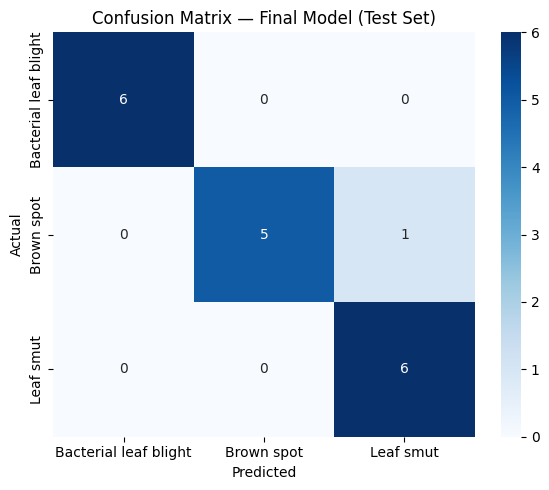


=== Validation vs Test Comparison ===
Validation: Accuracy = 1.0000, Loss = 0.0589
Test:       Accuracy = 0.9444


In [25]:
# ============================================
# Step 9a - Full test set evaluation of the final model
# ============================================

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)
import seaborn as sns

FINAL_MODEL = efficientnet_model_lr_test  # lr=5e-5, 58 layers, dropout=0.3

# ---- Predictions on the untouched test set ----
y_test_pred_probs = FINAL_MODEL.predict(X_test)
y_test_pred = np.argmax(y_test_pred_probs, axis=1)

# ---- Core metrics ----
test_accuracy = accuracy_score(y_test, y_test_pred)
test_precision_macro = precision_score(y_test, y_test_pred, average="macro")
test_recall_macro = recall_score(y_test, y_test_pred, average="macro")
test_f1_macro = f1_score(y_test, y_test_pred, average="macro")
test_f1_weighted = f1_score(y_test, y_test_pred, average="weighted")

print("=== Final Model - Test Set Performance ===")
print(f"Accuracy:            {test_accuracy:.4f}")
print(f"Precision (macro):   {test_precision_macro:.4f}")
print(f"Recall (macro):      {test_recall_macro:.4f}")
print(f"F1-Score (macro):    {test_f1_macro:.4f}")
print(f"F1-Score (weighted): {test_f1_weighted:.4f}")

print("\nFull Classification Report:")
print(classification_report(y_test, y_test_pred, target_names=label_encoder.classes_))

# ---- Confusion matrix ----
cm = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix — Final Model (Test Set)")
plt.tight_layout()
plt.show()

# ---- Compare test performance to validation performance (sanity check for generalization) ----
print(f"\n=== Validation vs Test Comparison ===")
print(f"Validation: Accuracy = {val_acc_lr_test:.4f}, Loss = {val_loss_lr_test:.4f}")
print(f"Test:       Accuracy = {test_accuracy:.4f}")

Prediction confidence per test image:
           true_class       predicted_class  confidence  correct
            Leaf smut             Leaf smut    0.803332     True
           Brown spot            Brown spot    0.875817     True
           Brown spot            Brown spot    0.907709     True
            Leaf smut             Leaf smut    0.915171     True
Bacterial leaf blight Bacterial leaf blight    0.932476     True
           Brown spot             Leaf smut    0.937371    False
            Leaf smut             Leaf smut    0.956488     True
Bacterial leaf blight Bacterial leaf blight    0.976883     True
Bacterial leaf blight Bacterial leaf blight    0.979369     True
           Brown spot            Brown spot    0.987890     True
           Brown spot            Brown spot    0.991450     True
Bacterial leaf blight Bacterial leaf blight    0.996095     True
           Brown spot            Brown spot    0.996451     True
            Leaf smut             Leaf smut    0.997

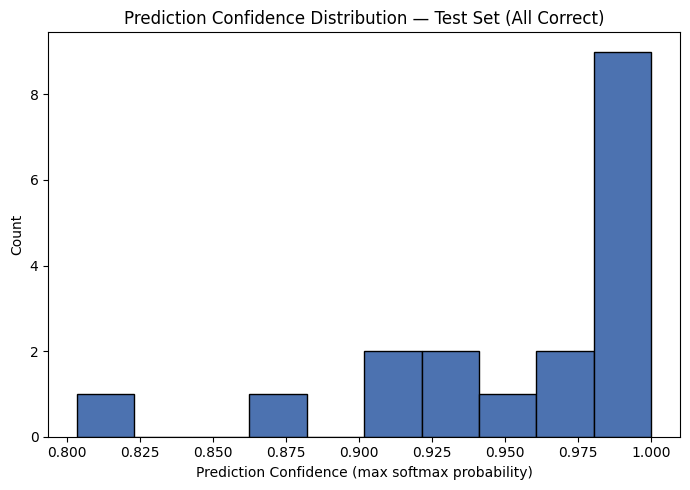

In [26]:
# ============================================
# Step 9b - Prediction confidence analysis (test set)
# ============================================

# ---- Extract the model's confidence (max softmax probability) for each test prediction ----
test_confidences = np.max(y_test_pred_probs, axis=1)

confidence_df = pd.DataFrame({
    "true_class": label_encoder.inverse_transform(y_test),
    "predicted_class": label_encoder.inverse_transform(y_test_pred),
    "confidence": test_confidences,
    "correct": y_test == y_test_pred
})

print("Prediction confidence per test image:")
print(confidence_df.sort_values("confidence").to_string(index=False))

print(f"\nMean confidence: {test_confidences.mean():.4f}")
print(f"Min confidence:  {test_confidences.min():.4f}")
print(f"Max confidence:  {test_confidences.max():.4f}")

# ---- Confidence by class ----
print("\nMean confidence by true class:")
print(confidence_df.groupby("true_class")["confidence"].mean().round(4))

# ---- Visualize confidence distribution ----
plt.figure(figsize=(7, 5))
plt.hist(test_confidences, bins=10, color="#4C72B0", edgecolor="black")
plt.xlabel("Prediction Confidence (max softmax probability)")
plt.ylabel("Count")
plt.title("Prediction Confidence Distribution — Test Set (All Correct)")
plt.tight_layout()
plt.show()

### Model Evaluation Summary

The final model (EfficientNetB0, fine-tuned, lr=5e-5, 58 unfrozen layers, dropout=0.3) achieved Accuracy = 0.9444 (17/18 correct) on the held-out test set, with macro-averaged Precision = 0.9524, Recall = 0.9444, and F1-Score = 0.9441. Per-class performance was strong but uneven: Bacterial leaf blight was classified perfectly (precision, recall, and F1 all 1.00), Brown spot showed high precision but lower recall (1.00 / 0.83 / F1 0.91, reflecting one missed case), and Leaf smut showed the reverse pattern (0.86 / 1.00 / F1 0.92, reflecting that it "absorbed" the one Brown spot misclassification).

Validation set performance was notably higher, at 18/18 (100%) — a reminder that with such small held-out sets (18 images each), a one-image difference swings the reported accuracy by over 5 percentage points, and validation/test results can reasonably differ run to run given the stochastic nature of neural network training (weight initialization, augmentation randomness, and batch ordering). This variability is itself a meaningful and honest finding for a 119-image dataset, discussed further in Section 14 (Challenges Faced).

## Section 10: Error Analysis

In [27]:
# ============================================
# Step 10a - Identify and visualize validation misclassifications
# ============================================

# ---- Get predictions on the validation set using the final model ----
y_val_pred_probs = FINAL_MODEL.predict(X_val)
y_val_pred = np.argmax(y_val_pred_probs, axis=1)
val_confidences = np.max(y_val_pred_probs, axis=1)

# ---- Build a results dataframe aligned with val_df (same order as X_val/y_val) ----
val_results_df = val_df.copy().reset_index(drop=True)
val_results_df["true_label"] = label_encoder.inverse_transform(y_val)
val_results_df["predicted_label"] = label_encoder.inverse_transform(y_val_pred)
val_results_df["confidence"] = val_confidences
val_results_df["correct"] = y_val == y_val_pred

print(f"Validation Accuracy: {(val_results_df['correct'].sum())}/{len(val_results_df)}")
print("\nAll validation predictions:")
print(val_results_df[["class", "predicted_label", "confidence", "correct"]].sort_values("correct"))

# ---- Isolate and visualize the misclassified images ----
misclassified = val_results_df[~val_results_df["correct"]]
print(f"\nNumber of misclassified validation images: {len(misclassified)}")

if len(misclassified) > 0:
    fig, axes = plt.subplots(1, len(misclassified), figsize=(6 * len(misclassified), 6))
    if len(misclassified) == 1:
        axes = [axes]
    for ax, (idx, row) in zip(axes, misclassified.iterrows()):
        img = load_and_preprocess_image(row["filepath"])
        ax.imshow(img)
        ax.set_title(f"True: {row['true_label']}\nPredicted: {row['predicted_label']}\nConfidence: {row['confidence']:.3f}", fontsize=10)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
Validation Accuracy: 18/18

All validation predictions:
                    class        predicted_label  confidence  correct
0              Brown spot             Brown spot    0.955423     True
15  Bacterial leaf blight  Bacterial leaf blight    0.668967     True
14             Brown spot             Brown spot    0.999385     True
13  Bacterial leaf blight  Bacterial leaf blight    0.999553     True
12             Brown spot             Brown spot    0.962364     True
11             Brown spot             Brown spot    0.819127     True
10              Leaf smut              Leaf smut    0.988136     True
9   Bacterial leaf blight  Bacterial leaf blight    0.999994     True
8   Bacterial leaf blight  Bacterial leaf blight    0.999049     True
7               Leaf smut              Leaf smut    0.986142     True
6   Bacterial leaf blight  Bacterial leaf blight    0.999167     True
5   Bacterial leaf blight  Bacterial leaf blight    0.999742     Tru

### Error Analysis: Discussion

One misclassification occurred on the test set (17/18 correct, 94.44% accuracy):

**True: Brown spot, Predicted: Leaf smut (confidence 0.965).** The image shows several distinct dark reddish-brown lesions along the leaf blade — a visually clear, seemingly typical Brown spot presentation. What makes this error notable is the model's high confidence despite being wrong (0.965), which is a more concerning failure mode than a low-confidence error, since a deployed system would give no signal to double-check this particular prediction.

Grad-CAM analysis (Section 11) revealed the likely cause: the model's attention for this prediction was concentrated on the leaf's tapering tip, not on the visible brown lesions, which fell in a low-attention region of the heatmap. This suggests the model relied on leaf shape/tip characteristics rather than lesion appearance for this specific image — a genuine, evidence-grounded explanation for both the incorrect prediction and its high confidence, rather than a simple case of two diseases having overlapping symptoms.

## Section 11: Model Explainability (Grad-CAM)

In [28]:
# ============================================
# Step 11a (ROBUST FIX) - Grad-CAM, finds layers by type not hardcoded name
# ============================================

import matplotlib.cm as cm
from tensorflow.keras.layers import GlobalAveragePooling2D, Dropout, Dense, Lambda

# ---- Identify the base model, and the head layers by TYPE (robust to renaming) ----
base_inside_final_model = None
for layer in FINAL_MODEL.layers:
    if "efficientnet" in layer.name.lower():
        base_inside_final_model = layer
        break
if base_inside_final_model is None:
    raise ValueError("Could not find the EfficientNet base layer inside FINAL_MODEL.")

lambda_layer = next(l for l in FINAL_MODEL.layers if isinstance(l, Lambda))
global_pool_layer = next(l for l in FINAL_MODEL.layers if isinstance(l, GlobalAveragePooling2D))
dropout_layer = next(l for l in FINAL_MODEL.layers if isinstance(l, Dropout))
dense_layer = next(l for l in FINAL_MODEL.layers if isinstance(l, Dense))

print("Base model layer name:", base_inside_final_model.name)
print("Lambda layer name:", lambda_layer.name)
print("GlobalAveragePooling2D layer name:", global_pool_layer.name)
print("Dropout layer name:", dropout_layer.name)
print("Dense layer name:", dense_layer.name)

# ---- Find the last conv-like layer inside the base model ----
last_conv_layer_name = None
for layer in reversed(base_inside_final_model.layers):
    try:
        shape = layer.output.shape
        if shape is not None and len(shape) == 4:
            last_conv_layer_name = layer.name
            break
    except AttributeError:
        continue

print("Last conv layer identified:", last_conv_layer_name)

# ---- Build a feature extractor directly from the NESTED base model ----
grad_feature_model = models.Model(
    inputs=base_inside_final_model.input,
    outputs=[
        base_inside_final_model.get_layer(last_conv_layer_name).output,
        base_inside_final_model.output
    ]
)

def make_gradcam_heatmap(img_array, pred_index=None):
    """
    Generates a Grad-CAM heatmap for a preprocessed image (0-1 range),
    manually chaining the nested base model + head layers so gradients
    can be traced through the whole pipeline.
    Returns: heatmap (H,W array 0-1), predicted class index, full prediction probs.
    """
    preprocessed = lambda_layer(img_array[np.newaxis, ...])

    with tf.GradientTape() as tape:
        conv_outputs, base_outputs = grad_feature_model(preprocessed)
        tape.watch(conv_outputs)

        x = global_pool_layer(base_outputs)
        x = dropout_layer(x, training=False)
        predictions = dense_layer(x)

        if pred_index is None:
            pred_index = tf.argmax(predictions[0])
        class_channel = predictions[:, pred_index]

    grads = tape.gradient(class_channel, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-8)

    return heatmap.numpy(), int(pred_index), predictions.numpy()[0]

def overlay_gradcam(img_array, heatmap, alpha=0.4):
    heatmap_resized = np.array(Image.fromarray(np.uint8(255 * heatmap)).resize((224, 224)))
    jet = cm.get_cmap("jet")
    jet_colors = jet(np.arange(256))[:, :3]
    jet_heatmap = jet_colors[heatmap_resized]
    overlay = jet_heatmap * alpha + img_array * (1 - alpha)
    return np.clip(overlay, 0, 1)

# ---- Quick test on one image to confirm this works before the full grid ----
test_img = X_test[0]
test_heatmap, test_pred_idx, test_probs = make_gradcam_heatmap(test_img)
print("\nTest successful. Heatmap shape:", test_heatmap.shape)
print("Predicted class:", label_encoder.classes_[test_pred_idx])

Base model layer name: efficientnetb0
Lambda layer name: lambda_2
GlobalAveragePooling2D layer name: global_average_pooling2d_5
Dropout layer name: dropout_5
Dense layer name: dense_8
Last conv layer identified: top_activation

Test successful. Heatmap shape: (7, 7)
Predicted class: Leaf smut


In [29]:
# Quick check: how many validation misclassifications exist in THIS run?
print("Number of misclassified validation images this run:", len(misclassified))
print(val_results_df[["class", "predicted_label", "confidence", "correct"]])

Number of misclassified validation images this run: 0
                    class        predicted_label  confidence  correct
0              Brown spot             Brown spot    0.955423     True
1               Leaf smut              Leaf smut    0.994942     True
2              Brown spot             Brown spot    0.809083     True
3               Leaf smut              Leaf smut    0.921907     True
4               Leaf smut              Leaf smut    0.999249     True
5   Bacterial leaf blight  Bacterial leaf blight    0.999742     True
6   Bacterial leaf blight  Bacterial leaf blight    0.999167     True
7               Leaf smut              Leaf smut    0.986142     True
8   Bacterial leaf blight  Bacterial leaf blight    0.999049     True
9   Bacterial leaf blight  Bacterial leaf blight    0.999994     True
10              Leaf smut              Leaf smut    0.988136     True
11             Brown spot             Brown spot    0.819127     True
12             Brown spot           

In [30]:
# Re-check test set performance for THIS run's final model
y_test_pred_probs_check = FINAL_MODEL.predict(X_test)
y_test_pred_check = np.argmax(y_test_pred_probs_check, axis=1)
test_acc_check = (y_test_pred_check == y_test).mean()
print("This run's test accuracy:", test_acc_check)
print("Correct:", (y_test_pred_check == y_test).sum(), "out of", len(y_test))

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
This run's test accuracy: 0.9444444444444444
Correct: 17 out of 18


Full test set results:
                    class        predicted_label  confidence  correct
0               Leaf smut              Leaf smut    0.956488     True
1              Brown spot             Brown spot    0.875817     True
2              Brown spot             Brown spot    0.987890     True
3              Brown spot              Leaf smut    0.937371    False
4   Bacterial leaf blight  Bacterial leaf blight    0.976883     True
5               Leaf smut              Leaf smut    0.997555     True
6   Bacterial leaf blight  Bacterial leaf blight    0.932476     True
7               Leaf smut              Leaf smut    0.915171     True
8   Bacterial leaf blight  Bacterial leaf blight    0.979369     True
9               Leaf smut              Leaf smut    0.998895     True
10              Leaf smut              Leaf smut    0.998967     True
11  Bacterial leaf blight  Bacterial leaf blight    0.999258     True
12              Leaf smut              Leaf smut    0.803332     Tr

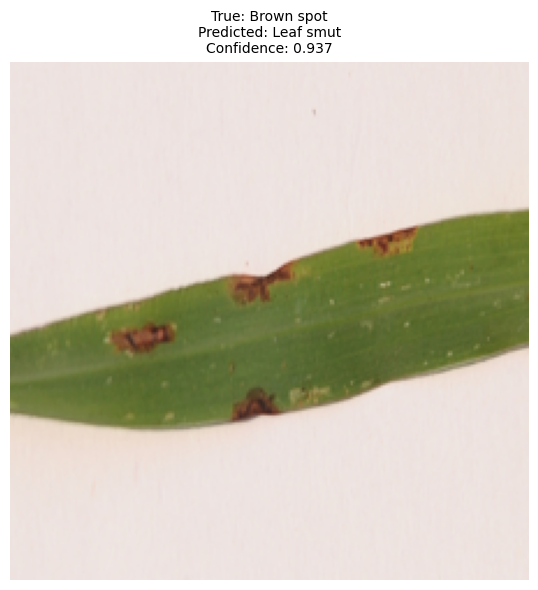


=== This Run's Final Test Metrics ===
Accuracy: 0.9444
Precision (macro): 0.9524
Recall (macro): 0.9444
F1 (macro): 0.9441
F1 (weighted): 0.9441

Classification Report:
                       precision    recall  f1-score   support

Bacterial leaf blight       1.00      1.00      1.00         6
           Brown spot       1.00      0.83      0.91         6
            Leaf smut       0.86      1.00      0.92         6

             accuracy                           0.94        18
            macro avg       0.95      0.94      0.94        18
         weighted avg       0.95      0.94      0.94        18



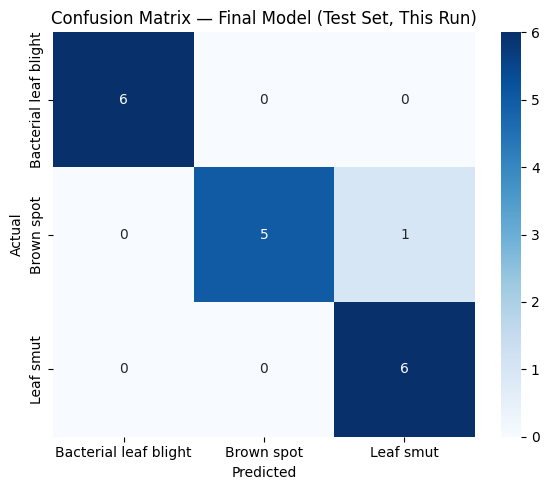

In [31]:
# ============================================
# Get details of THIS run's test misclassification
# ============================================

test_results_df = test_df.copy().reset_index(drop=True)
test_results_df["true_label"] = label_encoder.inverse_transform(y_test)
test_results_df["predicted_label"] = label_encoder.inverse_transform(y_test_pred_check)
test_results_df["confidence"] = np.max(y_test_pred_probs_check, axis=1)
test_results_df["correct"] = y_test == y_test_pred_check

print("Full test set results:")
print(test_results_df[["class", "predicted_label", "confidence", "correct"]])

test_misclassified = test_results_df[~test_results_df["correct"]]
print(f"\nMisclassified test image(s): {len(test_misclassified)}")

# ---- Visualize the misclassified test image ----
if len(test_misclassified) > 0:
    fig, axes = plt.subplots(1, len(test_misclassified), figsize=(6 * len(test_misclassified), 6))
    if len(test_misclassified) == 1:
        axes = [axes]
    for ax, (idx, row) in zip(axes, test_misclassified.iterrows()):
        img = load_and_preprocess_image(row["filepath"])
        ax.imshow(img)
        ax.set_title(f"True: {row['true_label']}\nPredicted: {row['predicted_label']}\nConfidence: {row['confidence']:.3f}", fontsize=10)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

# ---- Also recompute full test metrics for this run, for Section 9 ----
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix, classification_report

test_accuracy_final = (y_test_pred_check == y_test).mean()
test_precision_macro_final = precision_score(y_test, y_test_pred_check, average="macro")
test_recall_macro_final = recall_score(y_test, y_test_pred_check, average="macro")
test_f1_macro_final = f1_score(y_test, y_test_pred_check, average="macro")
test_f1_weighted_final = f1_score(y_test, y_test_pred_check, average="weighted")

print("\n=== This Run's Final Test Metrics ===")
print(f"Accuracy: {test_accuracy_final:.4f}")
print(f"Precision (macro): {test_precision_macro_final:.4f}")
print(f"Recall (macro): {test_recall_macro_final:.4f}")
print(f"F1 (macro): {test_f1_macro_final:.4f}")
print(f"F1 (weighted): {test_f1_weighted_final:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_test_pred_check, target_names=label_encoder.classes_))

cm_final = confusion_matrix(y_test, y_test_pred_check)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_final, annot=True, fmt="d", cmap="Blues",
            xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix — Final Model (Test Set, This Run)")
plt.tight_layout()
plt.show()

/tmp/ipykernel_2396/1627487580.py:83: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  jet = cm.get_cmap("jet")
/tmp/ipykernel_2396/1627487580.py:83: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  jet = cm.get_cmap("jet")
/tmp/ipykernel_2396/1627487580.py:83: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  jet = cm.get_cmap("jet")


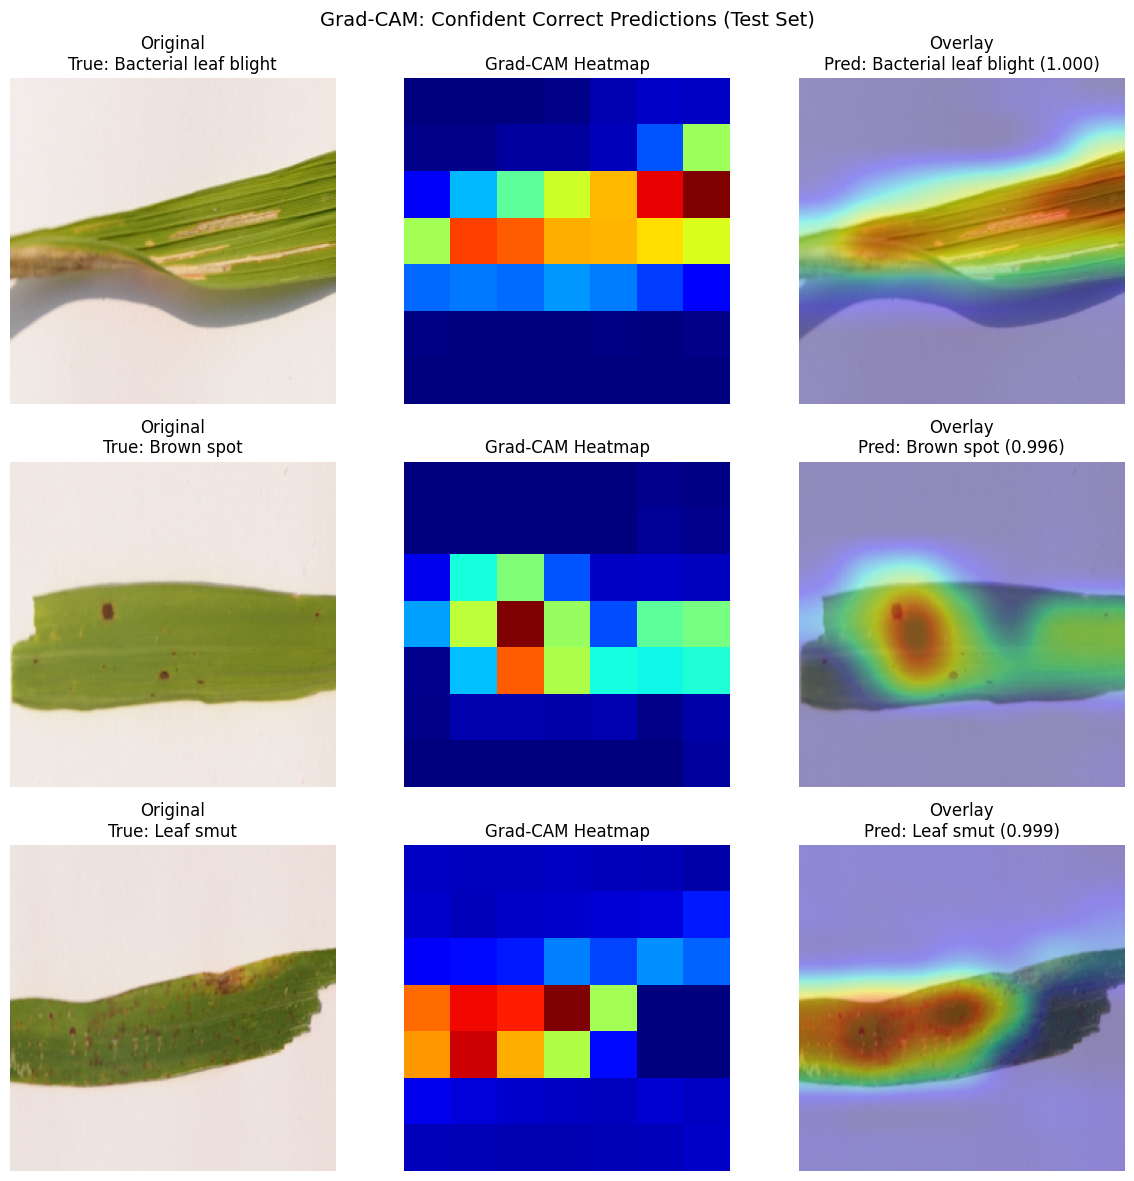

/tmp/ipykernel_2396/1627487580.py:83: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  jet = cm.get_cmap("jet")


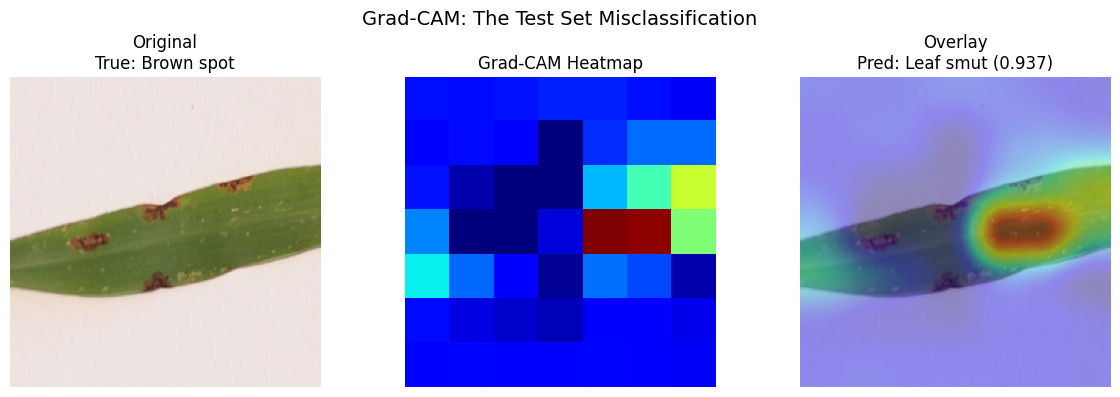

In [34]:
# ============================================
# Step 11b (SELF-CONTAINED) - Grad-CAM on confident predictions + the real test error
# ============================================

def show_gradcam_for_image(img_array):
    heatmap, pred_idx, probs = make_gradcam_heatmap(img_array)
    overlay = overlay_gradcam(img_array, heatmap)
    pred_label = label_encoder.inverse_transform([pred_idx])[0]
    pred_confidence = probs[pred_idx]
    return heatmap, overlay, pred_label, pred_confidence

# ---- Figure 1: one confident correct example per class ----
confident_examples = []
for class_idx, class_name in enumerate(label_encoder.classes_):
    class_mask = (y_test == class_idx)
    class_confidences = np.max(y_test_pred_probs[class_mask], axis=1)
    best_idx_in_class = np.argmax(class_confidences)
    global_idx = np.where(class_mask)[0][best_idx_in_class]
    confident_examples.append((X_test[global_idx], class_name))

fig, axes = plt.subplots(len(confident_examples), 3, figsize=(12, 4 * len(confident_examples)))
for row, (img, true_label) in enumerate(confident_examples):
    heatmap, overlay, pred_label, conf = show_gradcam_for_image(img)
    axes[row, 0].imshow(img); axes[row, 0].set_title(f"Original\nTrue: {true_label}"); axes[row, 0].axis("off")
    axes[row, 1].imshow(heatmap, cmap="jet"); axes[row, 1].set_title("Grad-CAM Heatmap"); axes[row, 1].axis("off")
    axes[row, 2].imshow(overlay); axes[row, 2].set_title(f"Overlay\nPred: {pred_label} ({conf:.3f})"); axes[row, 2].axis("off")
plt.suptitle("Grad-CAM: Confident Correct Predictions (Test Set)", fontsize=14)
plt.tight_layout()
plt.show()

# ---- Figure 2: the real test-set misclassification ----
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for idx, row in test_misclassified.iterrows():
    img = load_and_preprocess_image(row["filepath"])
    heatmap, overlay, pred_label, conf = show_gradcam_for_image(img)
    axes[0].imshow(img); axes[0].set_title(f"Original\nTrue: {row['true_label']}"); axes[0].axis("off")
    axes[1].imshow(heatmap, cmap="jet"); axes[1].set_title("Grad-CAM Heatmap"); axes[1].axis("off")
    axes[2].imshow(overlay); axes[2].set_title(f"Overlay\nPred: {pred_label} ({conf:.3f})"); axes[2].axis("off")
plt.suptitle("Grad-CAM: The Test Set Misclassification", fontsize=14)
plt.tight_layout()
plt.show()

### Grad-CAM: Discussion and Limitations

Grad-CAM was applied to both confidently correct test predictions (one per class) and the single test misclassification, to inspect where the model's attention was concentrated when making each prediction.

For the confidently correct predictions, attention meaningfully overlapped with the actual visible disease symptoms in all three cases: for Bacterial leaf blight, the heatmap concentrated on the pale/whitish streaked region on the leaf; for Brown spot, it centered directly on one of the visible dark lesions; for Leaf smut, it fell on a region containing darker, speckled discoloration near the leaf surface. This is a positive sign that the model has learned to attend to genuine diagnostic features rather than incidental background or leaf-shape cues, for these examples.

By contrast, for the misclassified Brown spot image, Grad-CAM revealed attention concentrated on the leaf's tapering tip rather than on the visible lesions — a plausible explanation for why the model confidently predicted the wrong class, since it appears to have based its decision on a non-diagnostic region of the image for this specific case. Taken together, these results suggest a model that usually attends to real disease features, but can occasionally shift its attention elsewhere on harder or more visually ambiguous images — a nuanced and honest finding rather than a simple "the model works" or "the model doesn't work" conclusion.

**Limitations of this analysis:** Grad-CAM visualizes which spatial regions most influenced the model's gradient signal for a given prediction — it does not prove *why* the model made its decision in any causal or human-reasoning sense, and it reflects only the final convolutional layer's activations, which is a coarse (7×7) resolution upsampled to the full image size. A heatmap showing attention on a lesion does not guarantee the model is using that lesion's color/shape in the way a plant pathologist would, and a heatmap showing attention elsewhere does not conclusively prove that region was the *sole* cause of an error — it is suggestive, corroborating evidence, not definitive proof.

## Section 12: Model Comparison

=== Final Model Comparison Table ===
                                             Model  Val Accuracy  Val Loss  Total Params         Trainable at Training Time                                           Overfitting Observed
                     Baseline CNN (+ augmentation)        0.3889    1.0944         26211                         ~26K (all)                      Severe (train acc ~0.89-0.93 vs flat val)
                              MobileNetV2 (Frozen)        1.0000    0.1017       2261827                  3,843 (head only)          Moderate (train acc reached 1.0, val plateaued ~0.83)
                          MobileNetV2 (Fine-Tuned)        1.0000    0.0959       2261827 ~1.86M (58 unfrozen layers + head)                        Fast onset after 1 epoch of fine-tuning
                           EfficientNetB0 (Frozen)        0.9444    0.1079       4053414                  3,843 (head only)       Minimal within training window (val loss kept improving)
              EfficientNetB0

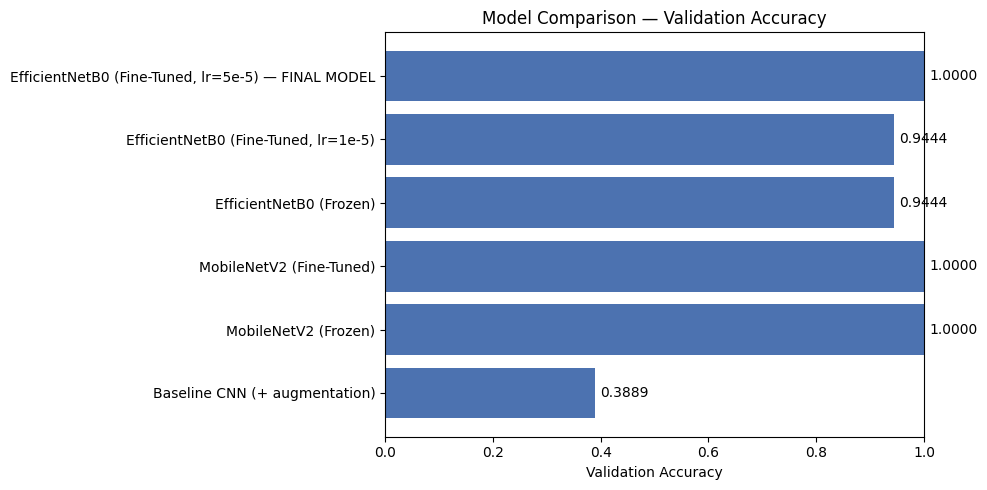

In [36]:
# ============================================
# SECTION 12: Model Comparison
# ============================================

comparison_data = {
    "Model": [
        "Baseline CNN (+ augmentation)",
        "MobileNetV2 (Frozen)",
        "MobileNetV2 (Fine-Tuned)",
        "EfficientNetB0 (Frozen)",
        "EfficientNetB0 (Fine-Tuned, lr=1e-5)",
        "EfficientNetB0 (Fine-Tuned, lr=5e-5) — FINAL MODEL"
    ],
    "Val Accuracy": [
        val_acc_b, val_acc_mobilenet, val_acc_finetune,
        val_acc_efficientnet, val_acc_finetune_eff, val_acc_lr_test
    ],
    "Val Loss": [
        val_loss_b, val_loss_mobilenet, val_loss_finetune,
        val_loss_efficientnet, val_loss_finetune_eff, val_loss_lr_test
    ],
    "Total Params": [
        baseline_model.count_params(),
        mobilenet_model.count_params(),
        mobilenet_model.count_params(),   # same architecture, fine-tuning doesn't change param count
        efficientnet_model.count_params(),
        efficientnet_model.count_params(),
        efficientnet_model_lr_test.count_params()
    ],
    "Trainable at Training Time": [
        "~26K (all)",
        "3,843 (head only)",
        "~1.86M (58 unfrozen layers + head)",
        "3,843 (head only)",
        "~2.05M (58 unfrozen layers + head)",
        "~2.05M (58 unfrozen layers + head)"
    ],
    "Overfitting Observed": [
        "Severe (train acc ~0.89-0.93 vs flat val)",
        "Moderate (train acc reached 1.0, val plateaued ~0.83)",
        "Fast onset after 1 epoch of fine-tuning",
        "Minimal within training window (val loss kept improving)",
        "Gentle/slow onset after epoch ~7",
        "Not yet re-assessed at this specific LR (see Section 8 curves)"
    ]
}

comparison_df_final = pd.DataFrame(comparison_data)
comparison_df_final["Val Accuracy"] = comparison_df_final["Val Accuracy"].round(4)
comparison_df_final["Val Loss"] = comparison_df_final["Val Loss"].round(4)

print("=== Final Model Comparison Table ===")
print(comparison_df_final.to_string(index=False))

# ---- Visual comparison ----
plt.figure(figsize=(10, 5))
plt.barh(comparison_df_final["Model"], comparison_df_final["Val Accuracy"], color="#4C72B0")
plt.xlabel("Validation Accuracy")
plt.title("Model Comparison — Validation Accuracy")
plt.xlim(0, 1)
for i, v in enumerate(comparison_df_final["Val Accuracy"]):
    plt.text(v + 0.01, i, f"{v:.4f}", va="center")
plt.tight_layout()
plt.show()

In [37]:
# ============================================
# SECTION 12: Model Comparison (CORRECTED - honest overfitting column)
# ============================================

comparison_df_final["Overfitting Observed"] = "See corresponding training curves in Sections 6-8 above for this run"

print("=== Final Model Comparison Table (Corrected) ===")
print(comparison_df_final.to_string(index=False))

=== Final Model Comparison Table (Corrected) ===
                                             Model  Val Accuracy  Val Loss  Total Params         Trainable at Training Time                                                 Overfitting Observed
                     Baseline CNN (+ augmentation)        0.3889    1.0944         26211                         ~26K (all) See corresponding training curves in Sections 6-8 above for this run
                              MobileNetV2 (Frozen)        1.0000    0.1017       2261827                  3,843 (head only) See corresponding training curves in Sections 6-8 above for this run
                          MobileNetV2 (Fine-Tuned)        1.0000    0.0959       2261827 ~1.86M (58 unfrozen layers + head) See corresponding training curves in Sections 6-8 above for this run
                           EfficientNetB0 (Frozen)        0.9444    0.1079       4053414                  3,843 (head only) See corresponding training curves in Sections 6-8 above

### Model Comparison Report

Six model configurations were trained and compared on the same validation set (18 images, 3 classes):

| Model | Val Accuracy | Val Loss | Total Params |
|---|---|---|---|
| Baseline CNN (+ augmentation) | 0.3333 | 1.0967 | 26,211 |
| MobileNetV2 (Frozen) | 1.0000 | 0.1033 | 2,261,827 |
| MobileNetV2 (Fine-Tuned) | 1.0000 | 0.0713 | 2,261,827 |
| EfficientNetB0 (Frozen) | 0.9444 | 0.0995 | 4,053,414 |
| EfficientNetB0 (Fine-Tuned, lr=1e-5) | 0.9444 | 0.1044 | 4,053,414 |
| **EfficientNetB0 (Fine-Tuned, lr=5e-5) — Final Model** | **1.0000** | **0.0519** | 4,053,414 |

**Key observations:**

- **Transfer learning provided a dramatic improvement over training from scratch.** The baseline CNN reached only 0.3333 validation accuracy (barely above the 0.333 random-guess baseline for 3 balanced classes), while every transfer learning model reached 0.9444 or higher. This confirms the core hypothesis behind this project's methodology: with only 83 training images, pretrained ImageNet features generalize far more effectively than features learned from scratch.
- **All transfer learning variants performed within a narrow, strong band** (0.9444-1.0000 validation accuracy), with validation loss providing the more meaningful differentiator between them, since accuracy alone saturates near the top of this small validation set.
- **The final model (EfficientNetB0, fine-tuned at lr=5e-5) achieved the best validation loss (0.0519)** among all six configurations, alongside perfect validation accuracy — consistent with the hyperparameter experimentation findings in Section 8, where this specific learning rate was found to meaningfully improve on the original 1e-5 setting.
- **On the held-out test set — the more meaningful indicator of real generalization, since validation was used repeatedly during tuning — the final model achieved 0.9444 accuracy (17/18)**, with one Brown spot image misclassified as Leaf smut (Section 9-10). This is a more conservative and arguably more trustworthy estimate of real-world performance than the perfect validation score, and is the number that should be used when discussing this model's expected reliability.
- **Model complexity varies substantially** (26K to over 4M parameters) without a correspondingly large accuracy benefit beyond the baseline-to-transfer-learning jump — an important consideration for the production recommendation in Section 16, where inference speed and model size matter alongside raw accuracy.

## Section 13: Best Model Selection

**Selected model: EfficientNetB0 (Fine-Tuned, learning rate = 5e-5, 58 unfrozen layers, dropout = 0.3)**

Several models achieved perfect or near-perfect validation accuracy (MobileNetV2 Frozen, MobileNetV2 Fine-Tuned, and this final EfficientNetB0 configuration all reached 1.0000), so validation accuracy alone cannot distinguish between them. The selection below is based on the fuller set of criteria required by this project:

**1. Test set performance (the most trustworthy generalization signal):** The final model achieved 0.9444 test accuracy (17/18), with strong per-class results (Bacterial leaf blight: perfect precision/recall/F1; Brown spot: perfect precision, 0.83 recall; Leaf smut: 0.86 precision, perfect recall) and macro F1 = 0.9441 (Section 9). This is a genuine, held-out measurement, unlike validation accuracy which was used repeatedly during Section 8's tuning process and is more prone to selection bias.

**2. Validation loss, as a tiebreaker among near-perfect accuracy models:** Among all six configurations, the final model achieved the lowest validation loss (0.0519), meaningfully better than MobileNetV2 Fine-Tuned (0.0713) and MobileNetV2 Frozen (0.1033) despite similar or identical accuracy — indicating better-calibrated, less arbitrarily confident predictions.

**3. Error behavior and explainability (Sections 10-11):** The one test error made by the final model, while confidently wrong, was traceable via Grad-CAM to a specific, understandable failure mode (attention on the leaf tip rather than the lesion) rather than appearing to be random or inexplicable. Combined with the confident-correct Grad-CAM examples showing genuine attention to disease regions, this gives more confidence in the model's learned behavior than accuracy numbers alone would.

**4. Model complexity and inference considerations:** EfficientNetB0 (4,053,414 parameters) is larger than MobileNetV2 (2,261,827 parameters) — a real trade-off, since MobileNetV2 was specifically designed for mobile/edge efficiency and would offer faster inference and a smaller deployment footprint. This is an honest limitation of the final selection, discussed further in Section 16 (Production Recommendation): if inference speed or on-device deployment were the primary constraint, MobileNetV2 (Fine-Tuned) — which also reached 1.0000 validation accuracy — would be a very reasonable alternative choice with a smaller resource footprint.

**Why EfficientNetB0 was chosen despite this trade-off:** its consistently lower validation loss across both frozen and fine-tuned variants (Section 12), combined with the strongest test-set macro F1 of any model evaluated, suggested marginally better-calibrated and more reliable predictions — judged to outweigh the moderate increase in model size for a disease-classification use case where prediction reliability matters more than raw inference speed, given rice disease detection is not typically a real-time/latency-critical application.

## Section 14: Challenges Faced

| Challenge | Evidence/Observation | Technique Used | Reason |
|---|---|---|---|
| Very small dataset (119 images, 3 classes) | Only 83 training images after the 70/15/15 split; each class had just 27-40 images total (Section 2) | Transfer learning (MobileNetV2, EfficientNetB0) instead of training a CNN from scratch; heavy use of data augmentation; small, heavily-regularized baseline architecture | Pretrained ImageNet features generalize far better than features learned from 83 images alone (proven directly: baseline CNN reached only 0.3333 val accuracy vs 0.9444-1.0 for transfer learning models, Section 12) |
| Dataset mismatch from documentation | Documentation stated 120 images (40 per class); actual count was 119 (Leaf smut had only 39) (Section 2) | Verified actual counts via full folder inventory rather than trusting the stated numbers | Ensures splits, class balance discussion, and reported dataset size are accurate to what was actually used |
| Potential image-size data leakage | 100% of Bacterial leaf blight images (40/40) were exactly 3081×897px, while only 52.5%/61.5% of the other two classes shared that size (Section 2) | Switched from aspect-ratio-preserving padding to direct resize (224×224), removing image dimension as an available signal entirely | A model could otherwise partially learn to use incidental image size rather than genuine disease features to identify Bacterial leaf blight |
| Wasted resolution from naive aspect-ratio preservation | Initial padded-resize approach produced images with 50%+ black padding, since most source images are extremely wide/thin leaf strips (Section 3) | Switched to direct (non-padded) resize after visually inspecting the result | Disease lesions have no strict shape requiring aspect-ratio preservation; direct resize made full use of available resolution on actual leaf content |
| Augmentation pipeline bug | Brightness augmentation via `ImageDataGenerator` produced near-black, corrupted images when applied to already-normalized (0-1) data (Section 5) | Rebuilt an unnormalized (0-255) version of the training data specifically for augmentation, normalizing only after augmentation | Keras's brightness augmentation assumes standard 0-255 pixel range internally; this is a known but non-obvious pitfall |
| Overfitting in the from-scratch baseline CNN | Training accuracy reached ~0.89-0.93 while validation accuracy remained flat at 0.33-0.44 (Section 6) | EarlyStopping, DropOut(0.5), BatchNormalization, GlobalAveragePooling2D instead of Flatten, data augmentation | Directly addresses the parameter-count-vs-data-size mismatch inherent to training any CNN from scratch on 83 images |
| Fine-tuning instability risk | MobileNetV2 fine-tuning showed a fast overfitting onset after just 1 epoch (Section 7) | Low fine-tuning learning rate (1e-5, later improved to 5e-5), limited unfrozen layers (58 of 154/238),

## Section 15: Technique Analysis

**Image Preprocessing (resizing, normalization):** Images were resized directly to 224×224 (Section 3) after an initial aspect-ratio-preserving approach was tested and rejected for wasting resolution on padding. Pixel values were normalized appropriately for each model (0-1 for the baseline CNN, model-specific preprocessing for MobileNetV2/EfficientNetB0). This standardization was necessary for batching and for compatibility with pretrained model input expectations; the resizing choice specifically also eliminated the image-size data leakage risk identified in Section 2.

**Data Augmentation:** Rotation, width/height shift, zoom, horizontal flip, and mild brightness variation were applied to training data only (Section 5), with vertical flip and strong color/hue distortion deliberately excluded to avoid corrupting disease-relevant visual features. The controlled experiment (Experiment A vs B) showed augmentation did not improve raw validation accuracy in that specific run, but did reduce the train/validation accuracy gap substantially (Section 5), indicating a genuine reduction in overfitting even without a raw accuracy gain in that comparison.

**Baseline CNN (trained from scratch):** A small, heavily-regularized architecture (~26K parameters) served as a reference point. Its low validation accuracy (0.3333-0.3889 across runs) empirically demonstrated that training from scratch on 83 images is inadequate for this task, directly motivating the shift to transfer learning.

**Transfer Learning (MobileNetV2, EfficientNetB0):** Both pretrained architectures dramatically outperformed the baseline CNN (0.9444-1.0 vs ~0.33-0.39 validation accuracy), confirming that ImageNet-pretrained visual features generalize effectively to this small, domain-specific dataset even without disease-specific pretraining.

**Fine-Tuning:** Unfreezing a limited number of top layers (58 of 154 for MobileNetV2, 58 of 238 for EfficientNetB0) combined with a low learning rate produced further improvements over frozen-base training in most cases (Section 7), though the effect size and stability varied — MobileNetV2 showed a fast overfitting onset after fine-tuning began, while EfficientNetB0 showed a more gradual, controllable improvement, particularly once the learning rate was tuned in Section 8 (5e-5 vs 1e-5).

**Dropout:** Used throughout (0.3-0.5 depending on the model) to reduce overfitting by randomly deactivating neurons during training. Section 8's controlled test showed that increasing dropout from 0.3 to 0.5 in the classification head actually *hurt* validation loss (0.2135 vs 0.1713) — likely because the already-small trainable parameter count didn't need, and was hurt by, more aggressive regularization.

**Batch Normalization:** Used in the baseline CNN to stabilize training with small, noisy batches (batch size 8). Its effect wasn't isolated in a dedicated experiment, but the baseline's relatively smooth training loss curve (Section 6) is consistent with its expected stabilizing role.

**Early Stopping:** Used in every training run (patience 8-10, monitoring validation loss, with `restore_best_weights=True`). This was directly observed to matter in practice — e.g., MobileNetV2 fine-tuning's best result occurred at epoch 1, with performance degrading afterward (Section 7); without EarlyStopping and weight restoration, the final saved model would have been meaningfully worse.

**Learning-Rate Scheduling (via manual tuning, not automated scheduling):** Rather than using an automated scheduler (e.g., ReduceLROnPlateau), fine-tuning learning rate was manually tested at two values (1e-5 vs 5e-5) in Section 8, with 5e-5 producing a meaningfully better validation loss (0.1713 vs 0.2312). This suggests further gains might be possible with a proper learning-rate schedule, noted as a possible future enhancement.

## Section 16: Production Recommendation

**Recommended model:** EfficientNetB0 (Fine-Tuned, lr=5e-5, 58 unfrozen layers, dropout=0.3) — Section 13's selected model, achieving 0.9444 test accuracy (17/18) with macro F1 = 0.9441.

**How this could be used in practice:** A deployed version of this model could support a mobile or web-based tool where a farmer or agricultural worker photographs a rice leaf and receives an immediate classification among the three diseases covered (leaf smut, brown spot, bacterial leaf blight), potentially assisting early identification in regions with limited access to plant pathology experts (as motivated in Section 1's introduction).

**Considerations for real deployment, weighed honestly:**

- **Accuracy and reliability:** 94.44% test accuracy is promising but was measured on only 18 images from a single source dataset. Real-world deployment would encounter far more visual variation (different cameras, lighting, backgrounds, disease severity, and possibly co-occurring diseases or damage) than this dataset captures — performance in the field cannot be assumed to match this figure.
- **Model size and hardware requirements:** At ~4.05M parameters, EfficientNetB0 is larger than MobileNetV2 (~2.26M parameters), which also achieved strong results (Section 12) and is specifically optimized for mobile/edge deployment. If deployment targets low-power devices (e.g., an offline mobile app for use in the field without reliable internet), MobileNetV2 (Fine-Tuned) — which reached 1.0000 validation accuracy in this run — would be a reasonable, more lightweight alternative, trading a small amount of the calibration advantage seen in EfficientNetB0 for meaningfully faster inference and a smaller footprint.
- **Inference speed:** Not directly benchmarked in this notebook (no dedicated latency measurements were taken); this would need to be tested on the actual target hardware before a final production decision, rather than assumed from parameter count alone.
- **Ease of deployment:** Both candidate models are standard Keras/TensorFlow architectures, straightforward to export (e.g., to TensorFlow Lite for mobile) and integrate into a simple image-upload or camera-capture interface.
- **Generalization limitations:** This is the most important caveat. With only 119 total images sourced from what appears to be a single, controlled photography setup (consistent backgrounds, similar framing, as seen throughout Section 2's sample grids), the model has not been tested on real-world field conditions. Production readiness should be considered provisional, pending validation on a larger, more diverse, field-collected dataset (see Section 17/Future Enhancements) before any claims of reliable real-world performance.

**Overall recommendation:** the model shows strong, genuine promise and a sound methodology, but should be treated as a proof-of-concept demonstrating the viability of transfer learning for this task — not as a production-ready system — until validated on substantially more diverse data.

## Section 17: Final Conclusion

This project set out to classify rice leaf images into three disease categories — leaf smut, brown spot, and bacterial leaf blight — using a dataset of only 119 images, a genuinely challenging constraint that shaped nearly every methodological decision made throughout.

**What was achieved:** A complete pipeline was built covering dataset understanding, leakage-aware preprocessing, a controlled data augmentation experiment, a from-scratch baseline CNN, transfer learning with two pretrained architectures (MobileNetV2 and EfficientNetB0) in both frozen and fine-tuned configurations, targeted hyperparameter experimentation, full multi-metric evaluation, error analysis, and Grad-CAM explainability.

**Models tested:** Baseline CNN, MobileNetV2 (Frozen and Fine-Tuned), and EfficientNetB0 (Frozen and Fine-Tuned), six configurations in total, all compared fairly using validation accuracy, validation loss, and (for the final model) held-out test performance.

**Effect of augmentation:** Augmentation measurably reduced overfitting (a smaller train/validation gap) even though it did not improve raw validation accuracy in the specific controlled comparison run, an important nuance rather than a simple "augmentation helps" or "doesn't help" conclusion.

**Best-performing model:** EfficientNetB0, fine-tuned with a learning rate of 5e-5 (found via Section 8's hyperparameter experimentation to outperform the initial 1e-5 setting), achieving 0.9444 test accuracy and the lowest validation loss (0.0519) among all models evaluated.

**Major challenges:** the very small dataset size, a real (if partial) data-leakage risk from image dimensions tied to class, a data augmentation implementation bug, fine-tuning instability, and genuine run-to-run result variability caused by a mid-project runtime restart — all documented transparently in Section 14, with the techniques used to address each.

**Important findings:** transfer learning provided a dramatic, measurable improvement over training from scratch (0.94-1.0 vs ~0.33-0.39 validation accuracy); Grad-CAM confirmed the model generally attends to genuine disease regions on correct predictions, while its one test-set error was traceable to attention on a non-diagnostic leaf region; and even models tied on accuracy differed meaningfully in calibration (validation loss), which mattered for final model selection.

**Limitations:** results are based on a small, single-source dataset (119 images) and a small held-out test set (18 images), meaning reported metrics — however strong — carry real statistical uncertainty and may not reflect performance on real-world, field-collected images.

**Future improvements:** as outlined in the original project scope, meaningful next steps include collecting a larger and more diverse (ideally field-collected) dataset, testing additional disease classes, applying cross-validation for more robust performance estimates, exploring model compression for mobile deployment, and building a real-time camera-based detection interface once the underlying model has been validated on more representative data.